# Is South Africa's Economy Really Recovering?

A data-driven investigation of South Africa's economic
performance relative to pre-pandemic levels.

**Author:** Shadreck Ngomane

**Data source:** Statistics South Africa (Stats SA)

## Research objectives

- Assess the recovery of real GDP.
- Compare pre-pandemic and post-pandemic economic growth.
- Examine changes in real GDP per capita.
- Evaluate labour-market recovery.
- Investigate consumer prices and real earnings.
- Assess whether aggregate economic recovery has translated
  into improved economic conditions for individuals.

## 1. Environment setup

Import the required libraries and define the project directories.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm

from matplotlib.patches import FancyBboxPatch

In [2]:
PROJECT_ROOT = Path.cwd().resolve().parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "figures"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
plt.rcParams.update({
    "figure.figsize": (12, 6),
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "font.size": 11,
    "legend.frameon": False,
    "savefig.dpi": 300
})

NAVY = "#17365D"
TEAL = "#247A73"
RED = "#B03A48"
GREY = "#555555"

In [4]:
gdp_file = RAW_DIR / "GDP P0441 - GDP Time series.xlsx"

population_file = RAW_DIR / "MYPE report table website_ 2026.xlsx"

qlfs_file = RAW_DIR / "QLFS Trends 2008-2026Q3.xlsx"

cpi_file = RAW_DIR / "Excel - CPI (COICOP) from January 2008 (202610).xlsx"

## 2. Real gross domestic product

Quarterly GDP data are obtained from Statistics South Africa's
P0441 time-series workbook.

Seasonally adjusted GDP is used to calculate quarter-on-quarter
growth, while unadjusted GDP is used to calculate year-on-year
growth and annual economic output.

The analysis covers 2010 Q1 to 2026 Q2, with earlier observations
retained during growth calculations.

In [5]:
quarterly = pd.read_excel(
    gdp_file,
    sheet_name="Quarterly",
    header=None
)

series_codes = {
    "QRS1000": "real_gdp_sa_annualised",
    "QRU1000": "real_gdp_unadjusted"
}

selected = quarterly.loc[
    quarterly[2].isin(series_codes)
].copy()

selected[[2, 4, 6, 7, 8]]

,2,4,6,7,8
145,QRU1000,GDP at market prices,Constant 2022 prices,Actual values,R million
200,QRS1000,GDP at market prices,Constant 2022 prices,Seasonally adjusted and annualised values,R million


### 2.1 Data preparation

The source workbook contains a duplicated 2018 Q3 header
and an omitted 2018 Q4 header.

Quarterly labels are reconstructed using the chronological
sequence of observation columns. Growth rates are calculated
before restricting the dataset to the study period.

In [6]:
quarter_codes = pd.to_numeric(
    quarterly.iloc[0, 10:],
    errors="coerce"
)

valid_columns = quarter_codes.index[
    (quarter_codes // 100).between(1993, 2026)
    & (quarter_codes % 100).isin([1, 2, 3, 4])
]

quarter_periods = pd.period_range(
    start="1993Q1",
    end="2026Q2",
    freq="Q"
)

assert len(valid_columns) == len(quarter_periods)

quarter_map = dict(zip(valid_columns, quarter_periods))

gdp_long = selected.melt(
    id_vars=2,
    value_vars=valid_columns,
    var_name="source_column",
    value_name="gdp_value"
)

gdp_long["quarter_period"] = (
    gdp_long["source_column"].map(quarter_map)
)

gdp_long["gdp_value"] = pd.to_numeric(
    gdp_long["gdp_value"],
    errors="coerce"
)

gdp_clean = (
    gdp_long.pivot(
        index="quarter_period",
        columns=2,
        values="gdp_value"
    )
    .rename(columns=series_codes)
    .sort_index()
    .reset_index()
)

gdp_clean.columns.name = None

gdp_clean.head()

,quarter_period,real_gdp_sa_annualised,real_gdp_unadjusted
0,1993Q1,3.504474e+06,860055.574543
1,1993Q2,3.528402e+06,881041.950707
2,1993Q3,3.573649e+06,901200.164942
3,1993Q4,3.604150e+06,910371.117216
4,1994Q1,3.602451e+06,876539.311157


In [7]:
gdp_clean["gdp_qoq_growth_pct"] = (
    gdp_clean["real_gdp_sa_annualised"]
    .pct_change(fill_method=None) * 100
)

gdp_clean["gdp_yoy_growth_pct"] = (
    gdp_clean["real_gdp_unadjusted"]
    .pct_change(periods=4, fill_method=None) * 100
)

gdp_clean = gdp_clean.loc[
    gdp_clean["quarter_period"].between(
        pd.Period("2010Q1"),
        pd.Period("2026Q2")
    )
].reset_index(drop=True)

gdp_clean.insert(
    0,
    "quarter",
    gdp_clean["quarter_period"].astype(str)
)

gdp_clean.tail()

,quarter,quarter_period,real_gdp_sa_annualised,real_gdp_unadjusted,gdp_qoq_growth_pct,gdp_yoy_growth_pct
61,2025Q2,2025Q2,7.127354e+06,1.783774e+06,0.747500,0.502256
62,2025Q3,2025Q3,7.149925e+06,1.804303e+06,0.316687,2.062679
63,2025Q4,2025Q4,7.175294e+06,1.821428e+06,0.354819,0.973526
64,2026Q1,2026Q1,7.213192e+06,1.757752e+06,0.528173,2.060975
65,2026Q2,2026Q2,7.193688e+06,1.802222e+06,-0.270392,1.034255


In [8]:
expected_quarters = pd.period_range(
    "2010Q1",
    "2026Q2",
    freq="Q"
)

gdp_columns = list(series_codes.values())

growth_columns = [
    "gdp_qoq_growth_pct",
    "gdp_yoy_growth_pct"
]

assert gdp_clean["quarter_period"].tolist() == list(expected_quarters)
assert gdp_clean[gdp_columns].gt(0).all().all()
assert np.isfinite(gdp_clean[growth_columns]).all().all()

gdp_clean.drop(columns="quarter_period").to_csv(
    PROCESSED_DIR / "south_africa_real_gdp_quarterly.csv",
    index=False
)

gdp_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 66 entries, 0 to 65
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype        
---  ------                  --------------  -----        
 0   quarter                 66 non-null     str          
 1   quarter_period          66 non-null     period[Q-DEC]
 2   real_gdp_sa_annualised  66 non-null     float64      
 3   real_gdp_unadjusted     66 non-null     float64      
 4   gdp_qoq_growth_pct      66 non-null     float64      
 5   gdp_yoy_growth_pct      66 non-null     float64      
dtypes: float64(4), period[Q-DEC](1), str(1)
memory usage: 3.2 KB


In [9]:
gdp_clean[growth_columns].describe().round(3)

,gdp_qoq_growth_pct,gdp_yoy_growth_pct
count,66.000,66.000
mean,0.334,1.252
std,2.980,3.696
min,-17.921,-17.761
25%,0.087,0.547
50%,0.461,1.195
75%,0.726,2.347
max,14.966,20.051


### 2.2 Historical GDP performance

Real GDP provides a measure of economic output adjusted for
price changes. The seasonally adjusted and annualised series
is used to examine quarterly economic performance and recovery
relative to the pre-pandemic period.

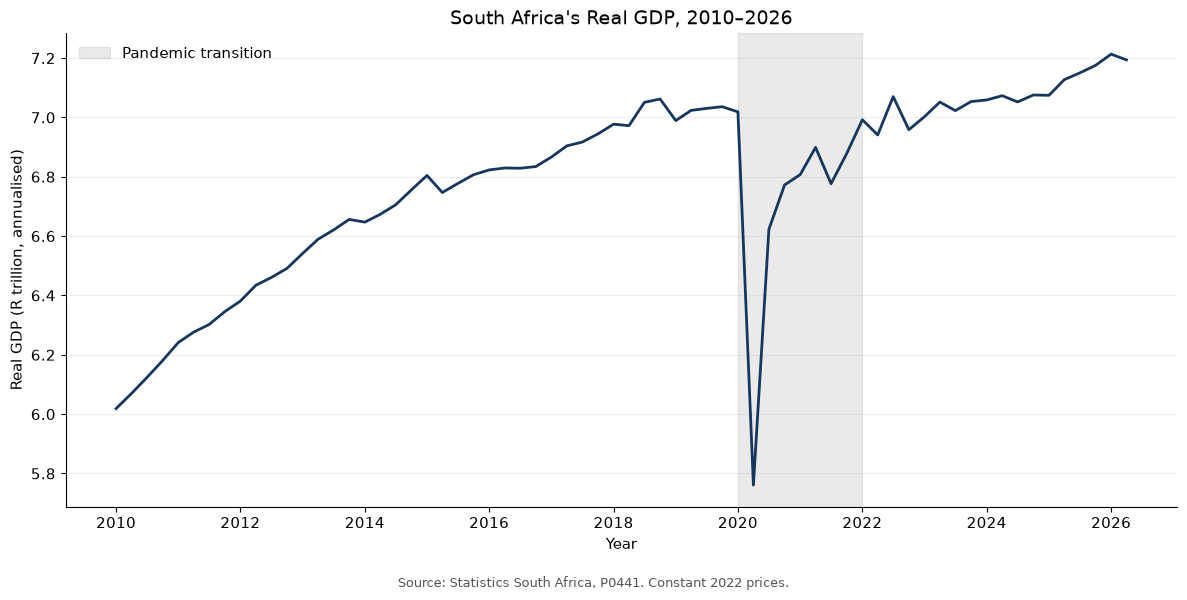

In [10]:
fig, ax = plt.subplots()

ax.plot(
    gdp_clean["quarter_period"].dt.to_timestamp(),
    gdp_clean["real_gdp_sa_annualised"] / 1e6,
    color=NAVY,
    linewidth=2
)

ax.axvspan(
    pd.Timestamp("2020-01-01"),
    pd.Timestamp("2022-01-01"),
    color=GREY,
    alpha=0.12,
    label="Pandemic transition"
)

ax.set(
    title="South Africa's Real GDP, 2010–2026",
    xlabel="Year",
    ylabel="Real GDP (R trillion, annualised)"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)

fig.text(
    0.5, 0.01,
    "Source: Statistics South Africa, P0441. Constant 2022 prices.",
    ha="center",
    fontsize=9,
    color=GREY
)

fig.tight_layout(rect=[0, 0.04, 1, 1])

fig.savefig(
    FIGURES_DIR / "01_sa_real_gdp_2010_2026.png",
    bbox_inches="tight"
)

plt.show()

### 2.3 Economic growth across periods

The study distinguishes between three economic periods:

- Pre-pandemic: 2010 Q1–2019 Q4.
- Pandemic transition: 2020 Q1–2021 Q4.
- Post-pandemic: 2022 Q1–2026 Q2.

These periods provide a consistent framework for comparing
quarterly economic growth.

In [11]:
period_labels = [
    "Pre-pandemic",
    "Pandemic transition",
    "Post-pandemic"
]

gdp_clean["economic_period"] = pd.cut(
    gdp_clean["quarter_period"].dt.year,
    bins=[2009, 2019, 2021, 2026],
    labels=period_labels
)

growth_summary = (
    gdp_clean.groupby("economic_period", observed=True)
    ["gdp_qoq_growth_pct"]
    .agg(
        observations="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
)

growth_summary.round(3)

,observations,mean,median,std,minimum,maximum
economic_period,,,,,,
Pre-pandemic,40,0.421,0.474,0.448,-1.031,1.167
Pandemic transition,8,0.080,0.931,8.926,-17.921,14.966
Post-pandemic,18,0.252,0.324,0.794,-1.578,1.862


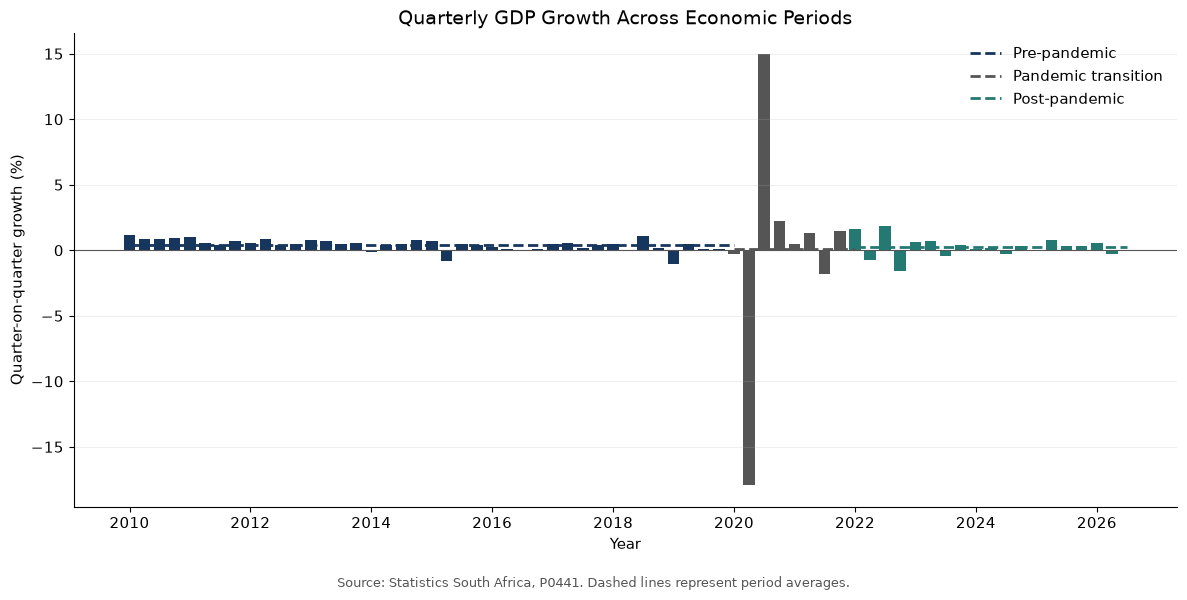

In [12]:
fig, ax = plt.subplots()

period_colors = {
    "Pre-pandemic": NAVY,
    "Pandemic transition": GREY,
    "Post-pandemic": TEAL
}

ax.bar(
    gdp_clean["quarter_period"].dt.to_timestamp(),
    gdp_clean["gdp_qoq_growth_pct"],
    width=70,
    color=gdp_clean["economic_period"].map(period_colors)
)

ax.axhline(0, color=GREY, linewidth=0.8)

for period, group in gdp_clean.groupby(
    "economic_period", observed=True
):
    ax.hlines(
        y=group["gdp_qoq_growth_pct"].mean(),
        xmin=group["quarter_period"].min().start_time,
        xmax=group["quarter_period"].max().end_time,
        color=period_colors[period],
        linestyle="--",
        linewidth=2,
        label=period
    )

ax.set(
    title="Quarterly GDP Growth Across Economic Periods",
    xlabel="Year",
    ylabel="Quarter-on-quarter growth (%)"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)

fig.text(
    0.5, 0.01,
    "Source: Statistics South Africa, P0441. "
    "Dashed lines represent period averages.",
    ha="center",
    fontsize=9,
    color=GREY
)

fig.tight_layout(rect=[0, 0.04, 1, 1])

fig.savefig(
    FIGURES_DIR / "02_gdp_growth_comparison.png",
    bbox_inches="tight"
)

plt.show()

### 2.4 Recovery relative to pre-pandemic output

Real GDP is indexed to 2019 Q4 to measure economic recovery
relative to the last quarter before the pandemic.

An index above 100 indicates that aggregate economic output
has exceeded its pre-pandemic level.

In [13]:
baseline_gdp = gdp_clean.loc[
    gdp_clean["quarter_period"] == pd.Period("2019Q4"),
    "real_gdp_sa_annualised"
].item()

gdp_clean["gdp_recovery_index"] = (
    gdp_clean["real_gdp_sa_annualised"] / baseline_gdp * 100
)

latest_gdp = gdp_clean.iloc[-1]

gdp_recovery_pct = latest_gdp["gdp_recovery_index"] - 100

pd.Series({
    "Baseline quarter": "2019Q4",
    "Comparison quarter": latest_gdp["quarter"],
    "Baseline GDP (R million)": round(baseline_gdp, 2),
    "Latest GDP (R million)": round(
        latest_gdp["real_gdp_sa_annualised"], 2
    ),
    "Recovery index": round(
        latest_gdp["gdp_recovery_index"], 2
    ),
    "Real GDP recovery (%)": round(gdp_recovery_pct, 2)
})

Baseline quarter                2019Q4
Comparison quarter              2026Q2
Baseline GDP (R million)    7036119.17
Latest GDP (R million)      7193688.35
Recovery index                  102.24
Real GDP recovery (%)             2.24
dtype: object

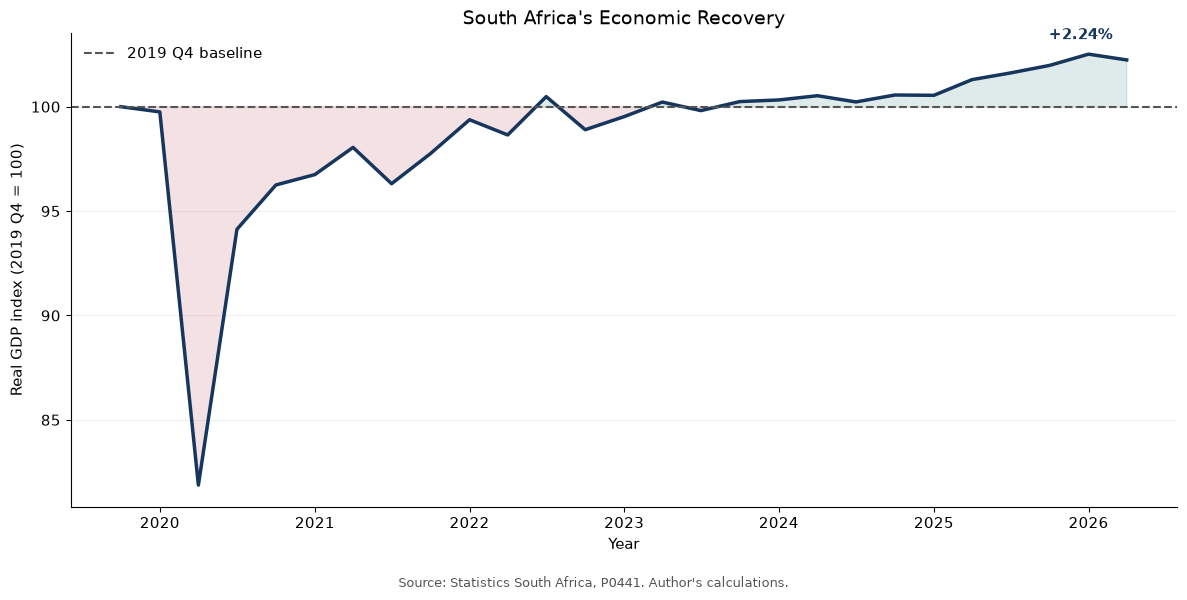

In [14]:
recovery = gdp_clean.loc[
    gdp_clean["quarter_period"] >= pd.Period("2019Q4")
]

dates = recovery["quarter_period"].dt.to_timestamp()
index = recovery["gdp_recovery_index"]

fig, ax = plt.subplots()

ax.plot(
    dates,
    index,
    color=NAVY,
    linewidth=2.5
)

ax.axhline(
    100,
    color=GREY,
    linestyle="--",
    label="2019 Q4 baseline"
)

ax.fill_between(
    dates,
    index,
    100,
    where=index >= 100,
    color=TEAL,
    alpha=0.15,
    interpolate=True
)

ax.fill_between(
    dates,
    index,
    100,
    where=index < 100,
    color=RED,
    alpha=0.15,
    interpolate=True
)

ax.annotate(
    f"{gdp_recovery_pct:+.2f}%",
    xy=(dates.iloc[-1], index.iloc[-1]),
    xytext=(-10, 15),
    textcoords="offset points",
    ha="right",
    color=NAVY,
    fontweight="bold"
)

ax.set(
    title="South Africa's Economic Recovery",
    xlabel="Year",
    ylabel="Real GDP index (2019 Q4 = 100)"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)

fig.text(
    0.5, 0.01,
    "Source: Statistics South Africa, P0441. "
    "Author's calculations.",
    ha="center",
    fontsize=9,
    color=GREY
)

fig.tight_layout(rect=[0, 0.04, 1, 1])

fig.savefig(
    FIGURES_DIR / "03_gdp_recovery_index.png",
    bbox_inches="tight"
)

plt.show()

## 3. Statistical analysis of economic recovery

### 3.1 Comparison of economic growth regimes

An ordinary least squares regression is used to assess whether
average quarterly GDP growth differs between the pre-pandemic
and post-pandemic periods.

The pandemic transition period is excluded from the comparison.

Heteroskedasticity and autocorrelation consistent (HAC) standard
errors are estimated using a maximum lag of four observations.

The null hypothesis is that average quarterly GDP growth is
equal across the two periods.

In [15]:
comparison = gdp_clean.loc[
    gdp_clean["economic_period"].isin([
        "Pre-pandemic",
        "Post-pandemic"
    ])
].copy()

comparison["post_pandemic"] = (
    comparison["economic_period"] == "Post-pandemic"
).astype(int)

X = sm.add_constant(comparison["post_pandemic"])
y = comparison["gdp_qoq_growth_pct"]

growth_model = sm.OLS(y, X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 4}
)

growth_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     gdp_qoq_growth_pct   R-squared:                       0.019
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     1.571
Date:                Tue, 24 Nov 2026   Prob (F-statistic):              0.215
Time:                        19:34:31   Log-Likelihood:                -49.221
No. Observations:                  58   AIC:                             102.4
Df Residuals:                      56   BIC:                             106.6
Df Model:                           1                                         
Covariance Type:                  HAC                                         
=================================================================================
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.4213      0.087      4.846      0.000       0.251       0.592
post_pandemic    -0.1690      0.135     -1.253      0.210      -0.433       0.095
==============================================================================
Omnibus:                        9.215   Durbin-Watson:                   2.655
Prob(Omnibus):                  0.010   Jarque-Bera (JB):               14.632
Skew:                          -0.444   Prob(JB):                     0.000665
Kurtosis:                       5.295   Cond. No.                         2.42
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity and autocorrelation robust (HAC) using 4 lags and without small sample correction
"""

In [16]:
pre_mean = growth_model.params["const"]

growth_difference = growth_model.params["post_pandemic"]

post_mean = pre_mean + growth_difference

growth_p_value = growth_model.pvalues["post_pandemic"]

growth_ci = growth_model.conf_int().loc["post_pandemic"]

growth_comparison = pd.Series({
    "Pre-pandemic mean (%)": pre_mean,
    "Post-pandemic mean (%)": post_mean,
    "Mean difference (pp)": growth_difference,
    "HAC standard error": growth_model.bse["post_pandemic"],
    "p-value": growth_p_value,
    "95% CI lower bound": growth_ci.iloc[0],
    "95% CI upper bound": growth_ci.iloc[1]
})

growth_comparison.round(4)

Pre-pandemic mean (%)     0.4213
Post-pandemic mean (%)    0.2523
Mean difference (pp)     -0.1690
HAC standard error        0.1348
p-value                   0.2101
95% CI lower bound       -0.4333
95% CI upper bound        0.0953
dtype: float64

In [17]:
pre_mean = growth_model.params["const"]

growth_difference = growth_model.params["post_pandemic"]

post_mean = pre_mean + growth_difference

growth_p_value = growth_model.pvalues["post_pandemic"]

growth_ci = growth_model.conf_int().loc["post_pandemic"]

growth_comparison = pd.Series({
    "Pre-pandemic mean (%)": pre_mean,
    "Post-pandemic mean (%)": post_mean,
    "Mean difference (pp)": growth_difference,
    "HAC standard error": growth_model.bse["post_pandemic"],
    "p-value": growth_p_value,
    "95% CI lower bound": growth_ci.iloc[0],
    "95% CI upper bound": growth_ci.iloc[1]
})

growth_comparison.round(4)

Pre-pandemic mean (%)     0.4213
Post-pandemic mean (%)    0.2523
Mean difference (pp)     -0.1690
HAC standard error        0.1348
p-value                   0.2101
95% CI lower bound       -0.4333
95% CI upper bound        0.0953
dtype: float64

#### Interpretation

Average quarterly GDP growth declined from 0.421% before the
pandemic to 0.252% during the post-pandemic period.

The estimated difference of -0.169 percentage points is not
statistically significant at the 5% level (p = 0.210).

This does not establish that the two growth regimes are
equivalent. Rather, the available evidence is insufficient
to conclude that their average growth rates differ.

The HAC estimator treats the retained observations as
consecutive despite the excluded pandemic transition period.
This limitation should be considered when interpreting
statistical inference.

### 3.2 Historical GDP trend and sensitivity analysis

A log-linear regression is fitted to historical real GDP
to estimate its underlying growth trajectory.

Three estimation windows are considered:

- 2010 Q1–2019 Q4
- 2013 Q1–2019 Q4
- 2015 Q1–2019 Q4

Each estimated trend is extrapolated to 2026 Q2 and compared
with observed real GDP.

The alternative estimation windows assess the sensitivity
of the estimated GDP gap to the historical reference period.

These extrapolations are descriptive benchmarks rather
than causal estimates of economic losses.

In [18]:
trend_df = gdp_clean.copy()
trend_df["time"] = np.arange(len(trend_df))

windows = {
    "2010-2019": "2010Q1",
    "2013-2019": "2013Q1",
    "2015-2019": "2015Q1"
}

trend_models = {}
trend_results = []

latest = trend_df.iloc[-1]

forecast_X = pd.DataFrame({
    "const": [1.0],
    "time": [latest["time"]]
})

for scenario, start in windows.items():

    train = trend_df.loc[
        trend_df["quarter_period"].between(
            pd.Period(start),
            pd.Period("2019Q4")
        )
    ]

    X = sm.add_constant(train[["time"]])
    y = np.log(train["real_gdp_sa_annualised"])

    model = sm.OLS(y, X).fit()

    trend_models[scenario] = model

    predicted_gdp = np.exp(
        model.predict(forecast_X).item()
    )

    actual_gdp = latest["real_gdp_sa_annualised"]

    trend_results.append({
        "scenario": scenario,
        "observations": len(train),
        "quarterly_trend_growth_pct": np.expm1(
            model.params["time"]
        ) * 100,
        "predicted_gdp_r_million": predicted_gdp,
        "actual_gdp_r_million": actual_gdp,
        "gap_pct": (actual_gdp / predicted_gdp - 1) * 100,
        "r_squared": model.rsquared,
        "durbin_watson": sm.stats.stattools.durbin_watson(
            model.resid
        )
    })

sensitivity_results = pd.DataFrame(trend_results)

sensitivity_results.to_csv(
    PROCESSED_DIR / "gdp_trend_sensitivity.csv",
    index=False
)

sensitivity_results.round(3)

,scenario,observations,quarterly_trend_growth_pct,predicted_gdp_r_million,actual_gdp_r_million,gap_pct,r_squared,durbin_watson
0,2010-2019,40,0.379,7913165.800,7193688.355,-9.092,0.938,0.143
1,2013-2019,28,0.265,7589156.742,7193688.355,-5.211,0.961,1.023
2,2015-2019,20,0.238,7519780.322,7193688.355,-4.336,0.917,1.227


In [19]:
trend_model = trend_models["2010-2019"]

trend_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                              OLS Regression Results                              
==================================================================================
Dep. Variable:     real_gdp_sa_annualised   R-squared:                       0.938
Model:                                OLS   Adj. R-squared:                  0.936
Method:                     Least Squares   F-statistic:                     572.5
Date:                    Tue, 24 Nov 2026   Prob (F-statistic):           1.62e-24
Time:                            19:38:44   Log-Likelihood:                 122.73
No. Observations:                      40   AIC:                            -241.5
Df Residuals:                          38   BIC:                            -238.1
Df Model:                               1                                         
Covariance Type:                nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         15.6381      0.004   4364.307      0.000      15.631      15.645
time           0.0038      0.000     23.928      0.000       0.003       0.004
==============================================================================
Omnibus:                        2.183   Durbin-Watson:                   0.143
Prob(Omnibus):                  0.336   Jarque-Bera (JB):                1.986
Skew:                          -0.522   Prob(JB):                        0.370
Kurtosis:                       2.682   Cond. No.                         44.5
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [20]:
X_full = sm.add_constant(
    trend_df[["time"]],
    has_constant="add"
)

trend_df["counterfactual_gdp"] = np.exp(
    trend_model.predict(X_full)
)

trend_df["gap_pct"] = (
    trend_df["real_gdp_sa_annualised"]
    / trend_df["counterfactual_gdp"] - 1
) * 100

trend_df[[
    "quarter",
    "real_gdp_sa_annualised",
    "counterfactual_gdp",
    "gap_pct"
]].tail().round(2)

,quarter,real_gdp_sa_annualised,counterfactual_gdp,gap_pct
61,2025Q2,7127353.59,7794308.40,-8.56
62,2025Q3,7149924.97,7823854.32,-8.61
63,2025Q4,7175294.25,7853512.25,-8.64
64,2026Q1,7213192.25,7883282.60,-8.50
65,2026Q2,7193688.35,7913165.80,-9.09


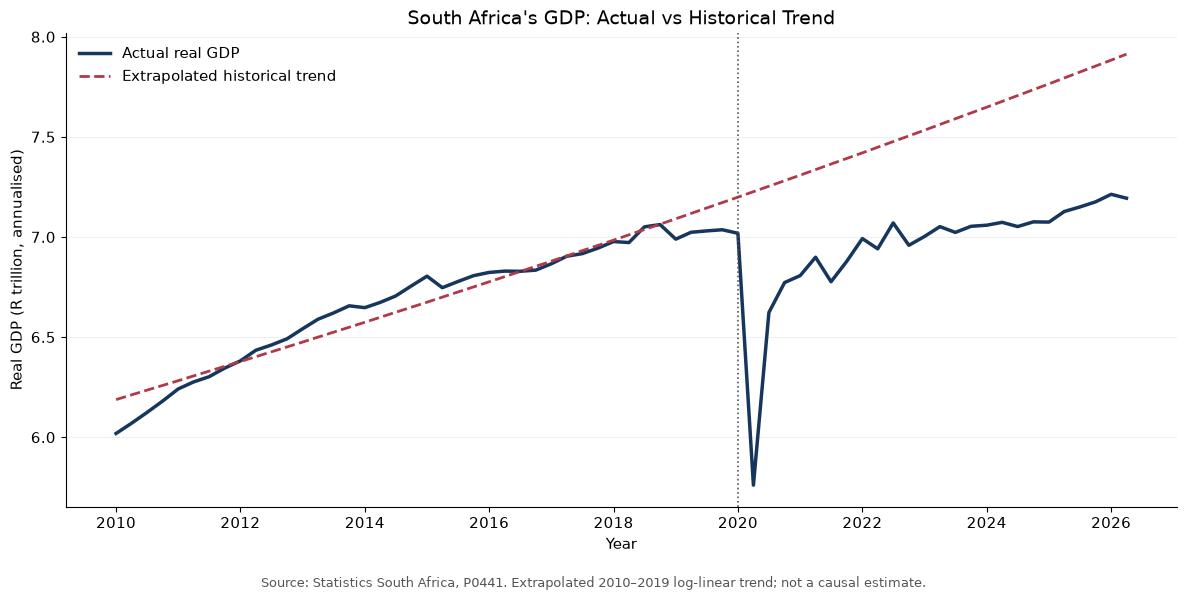

In [21]:
fig, ax = plt.subplots()

dates = trend_df["quarter_period"].dt.to_timestamp()

ax.plot(
    dates,
    trend_df["real_gdp_sa_annualised"] / 1e6,
    color=NAVY,
    linewidth=2.5,
    label="Actual real GDP"
)

ax.plot(
    dates,
    trend_df["counterfactual_gdp"] / 1e6,
    color=RED,
    linestyle="--",
    linewidth=2,
    label="Extrapolated historical trend"
)

ax.axvline(
    pd.Timestamp("2020-01-01"),
    color=GREY,
    linestyle=":",
    linewidth=1.2
)

ax.set(
    title="South Africa's GDP: Actual vs Historical Trend",
    xlabel="Year",
    ylabel="Real GDP (R trillion, annualised)"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)

fig.text(
    0.5, 0.01,
    "Source: Statistics South Africa, P0441. "
    "Extrapolated 2010–2019 log-linear trend; "
    "not a causal estimate.",
    ha="center",
    fontsize=9,
    color=GREY
)

fig.tight_layout(rect=[0, 0.04, 1, 1])

fig.savefig(
    FIGURES_DIR / "04_actual_vs_counterfactual_gdp.png",
    bbox_inches="tight"
)

plt.show()

#### Interpretation

Real GDP in 2026 Q2 remains below the extrapolated historical
trend across all three estimation windows.

The estimated shortfall ranges from 4.34% to 9.09%, indicating
that its magnitude is sensitive to the selected reference
period.

The Durbin–Watson statistics indicate positive residual
autocorrelation, particularly in the 2010–2019 model.

Consequently, these trend extrapolations are interpreted
as historical benchmarks rather than reliable forecasts
or causal estimates of pandemic-related economic losses.

## 4. Population and real GDP per capita

Aggregate GDP growth does not necessarily translate into
higher economic output per person.

Population estimates are obtained from Statistics South Africa's
2026 Mid-Year Population Estimates (MYPE).

Historical population estimates are reconstructed backwards
from the 2026 national population using published annual
population growth rates.

In [22]:
pop_table = pd.read_excel(
    population_file,
    sheet_name="MYPE by pop grp and sex",
    header=None
)

population_2026 = int(pop_table.iloc[7, 5])

growth_table = pd.read_excel(
    population_file,
    sheet_name="Rate of Growth by age grp",
    header=None
)

population_rates = growth_table.iloc[1:, [1, 6]].copy()
population_rates.columns = ["period", "growth_pct"]

population_rates["year"] = (
    population_rates["period"]
    .astype(str)
    .str.findall(r"\d{4}")
    .str[-1]
    .astype(int)
)

population_rates["growth_pct"] = pd.to_numeric(
    population_rates["growth_pct"],
    errors="coerce"
)

population_rates = (
    population_rates[["year", "growth_pct"]]
    .dropna()
    .set_index("year")
    .sort_index()
)

assert population_rates.index.is_unique
assert set(range(2011, 2027)).issubset(population_rates.index)

population_rates.tail()

,growth_pct
year,
2022,1.05
2023,1.16
2024,1.23
2025,1.25
2026,1.20


### 4.1 Historical population reconstruction

Historical population estimates are calculated using:

$$
P_{t-1} = \frac{P_t}{1 + g_t}
$$

where $P_t$ is the population in year $t$ and $g_t$ is
the annual population growth rate expressed as a decimal.

Since the published growth rates are rounded, the reconstructed
population series represents approximate historical estimates
rather than directly published annual population counts.

In [23]:
population = {2026: float(population_2026)}

for year in range(2026, 2010, -1):
    rate = population_rates.loc[year, "growth_pct"] / 100
    population[year - 1] = population[year] / (1 + rate)

population_df = (
    pd.Series(population, name="population")
    .rename_axis("year")
    .sort_index()
    .reset_index()
)

population_df["population"] = (
    population_df["population"].round().astype("int64")
)

population_df["population_millions"] = (
    population_df["population"] / 1e6
)

assert len(population_df) == 17
assert population_df["population"].gt(0).all()
assert population_df["population"].is_monotonic_increasing
assert population_df.iloc[-1]["population"] == population_2026

population_df.to_csv(
    PROCESSED_DIR / "south_africa_population_2010_2026.csv",
    index=False
)

population_df.round(3)

,year,population,population_millions
0,2010,51151496,51.151
1,2011,51913653,51.914
2,2012,52744271,52.744
3,2013,53572356,53.572
4,2014,54418800,54.419
5,2015,55240523,55.241
6,2016,56002843,56.003
7,2017,56775682,56.776
8,2018,57604607,57.605
9,2019,58474436,58.474


### 4.2 Annual real GDP per capita

Annual real GDP is calculated as the average of the four
seasonally adjusted and annualised quarterly GDP observations.

Real GDP per capita is then calculated as:

$$
GDP_{pc,t} = \frac{GDP_t}{P_t}
$$

GDP is expressed in constant 2022 rand.

Only complete calendar years are included, restricting the
annual analysis to 2010–2025.

In [24]:
annual_gdp = (
    gdp_clean.assign(
        year=gdp_clean["quarter_period"].dt.year
    )
    .groupby("year", as_index=False)
    .agg(
        real_gdp_r_million=("real_gdp_sa_annualised", "mean"),
        quarters_observed=("quarter", "nunique")
    )
)

annual_gdp = (
    annual_gdp.loc[annual_gdp["quarters_observed"] == 4]
    .drop(columns="quarters_observed")
)

annual_gdp.tail()

,year,real_gdp_r_million
11,2021,6.840301e+06
12,2022,6.990436e+06
13,2023,7.032661e+06
14,2024,7.064920e+06
15,2025,7.131761e+06


In [25]:
annual = annual_gdp.merge(
    population_df[["year", "population"]],
    on="year",
    how="inner",
    validate="one_to_one"
)

annual["real_gdp_per_capita"] = (
    annual["real_gdp_r_million"] * 1e6
    / annual["population"]
)

gdp_pc_2019 = annual.loc[
    annual["year"] == 2019,
    "real_gdp_per_capita"
].item()

annual["gdp_per_capita_index_2019"] = (
    annual["real_gdp_per_capita"] / gdp_pc_2019 * 100
)

assert annual["year"].tolist() == list(range(2010, 2026))
assert annual["real_gdp_per_capita"].gt(0).all()

annual.to_csv(
    PROCESSED_DIR / "sa_real_gdp_per_capita_2010_2025.csv",
    index=False
)

annual.round(2)

,year,real_gdp_r_million,population,real_gdp_per_capita,gdp_per_capita_index_2019
0,2010,6097905.40,51151496,119212.65,99.30
1,2011,6291120.96,51913653,121184.32,100.95
2,2012,6441870.84,52744271,122134.04,101.74
3,2013,6601981.48,53572356,123234.85,102.65
4,2014,6695322.04,54418800,123033.25,102.49
5,2015,6783824.98,55240523,122805.23,102.30
6,2016,6828907.04,56002843,121938.58,101.57
7,2017,6907982.16,56775682,121671.50,101.35
8,2018,7015524.51,57604607,121787.56,101.45
9,2019,7019825.91,58474436,120049.48,100.00


In [26]:
indicators = [
    "real_gdp_r_million",
    "population",
    "real_gdp_per_capita"
]

annual_comparison = (
    annual.set_index("year")
    .loc[[2019, 2025], indicators]
    .T
)

annual_comparison["change_pct"] = (
    annual_comparison[2025] / annual_comparison[2019] - 1
) * 100

annual_gdp_growth_pct = annual_comparison.loc[
    "real_gdp_r_million", "change_pct"
]

population_growth_pct = annual_comparison.loc[
    "population", "change_pct"
]

gdp_pc_growth_pct = annual_comparison.loc[
    "real_gdp_per_capita", "change_pct"
]

annual_comparison.round(2)

year,2019,2025,change_pct
real_gdp_r_million,7019825.91,7131761.19,1.59
population,58474436.00,62769150.00,7.34
real_gdp_per_capita,120049.48,113618.89,-5.36


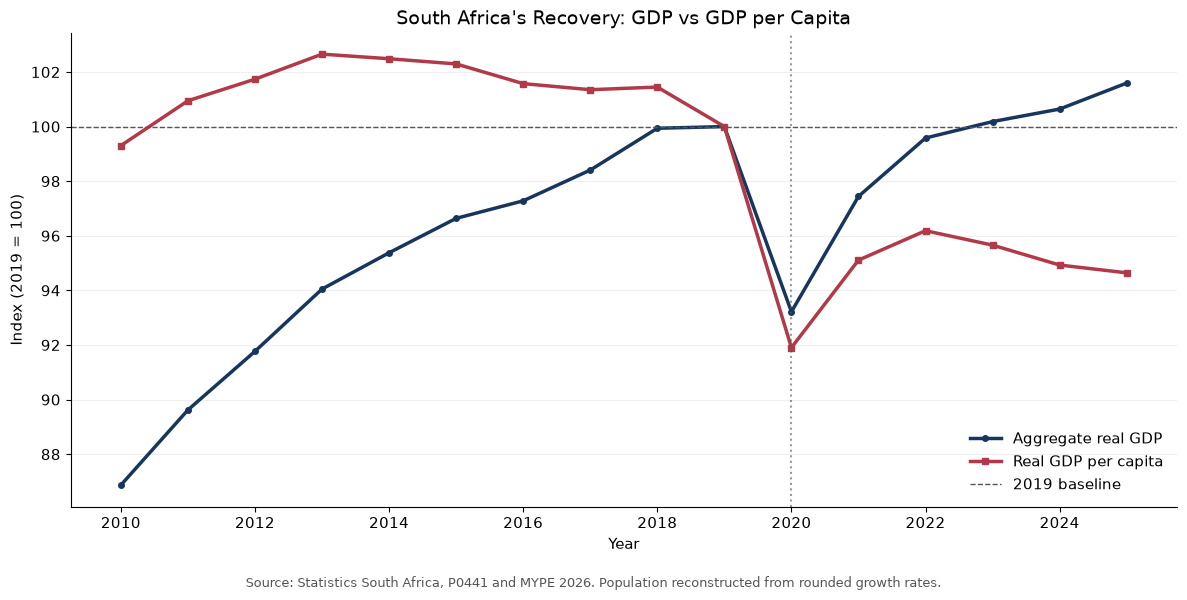

In [27]:
gdp_2019 = annual.loc[
    annual["year"] == 2019,
    "real_gdp_r_million"
].item()

aggregate_gdp_index = (
    annual["real_gdp_r_million"] / gdp_2019 * 100
)

fig, ax = plt.subplots()

ax.plot(
    annual["year"],
    aggregate_gdp_index,
    color=NAVY,
    linewidth=2.5,
    marker="o",
    markersize=4,
    label="Aggregate real GDP"
)

ax.plot(
    annual["year"],
    annual["gdp_per_capita_index_2019"],
    color=RED,
    linewidth=2.5,
    marker="s",
    markersize=4,
    label="Real GDP per capita"
)

ax.axhline(
    100,
    color=GREY,
    linestyle="--",
    linewidth=1,
    label="2019 baseline"
)

ax.axvline(
    2020,
    color=GREY,
    linestyle=":",
    alpha=0.6
)

ax.set(
    title="South Africa's Recovery: GDP vs GDP per Capita",
    xlabel="Year",
    ylabel="Index (2019 = 100)",
    xticks=range(2010, 2026, 2)
)

ax.legend()
ax.grid(axis="y", alpha=0.2)

fig.text(
    0.5, 0.01,
    "Source: Statistics South Africa, P0441 and MYPE 2026. "
    "Population reconstructed from rounded growth rates.",
    ha="center",
    fontsize=9,
    color=GREY
)

fig.tight_layout(rect=[0, 0.04, 1, 1])

fig.savefig(
    FIGURES_DIR / "05_gdp_vs_gdp_per_capita.png",
    bbox_inches="tight"
)

plt.show()

#### Interpretation

Between 2019 and 2025, aggregate real GDP increased by 1.59%,
while the estimated population increased by 7.34%.

Consequently, real GDP per capita declined by 5.36%, from
approximately R120,049 to R113,619 in constant 2022 prices.

Although aggregate economic output recovered beyond its
pre-pandemic level, economic output per person remained lower.

GDP per capita measures average economic output per person.
It does not directly measure household income, wealth,
income distribution or individual living standards.

## 5. Labour-market recovery

Quarterly labour-market data are obtained from Statistics
South Africa's Quarterly Labour Force Survey (QLFS).

The analysis covers 2010 Q1 to 2026 Q3 and focuses on national
employment, unemployment, labour force participation and
the employment-to-population ratio.

Recovery is assessed by comparing 2019 Q3 with 2026 Q3
to maintain consistency in the seasonal reference period.

In [28]:
qlfs_raw = pd.read_excel(
    qlfs_file,
    sheet_name="Table 2",
    header=None
)

quarter_map = {
    "Jan-Mar": 1,
    "Apr-Jun": 2,
    "Jul-Sep": 3,
    "Oct-Dec": 4
}

quarter_labels = qlfs_raw.iloc[1, 1:].astype(str).str.strip()

quarter_parts = quarter_labels.str.extract(
    r"^(Jan-Mar|Apr-Jun|Jul-Sep|Oct-Dec)\s+(\d{4})$"
).dropna()

quarter_parts.columns = ["period", "year"]

quarter_parts["year"] = quarter_parts["year"].astype(int)

quarter_parts["quarter_number"] = (
    quarter_parts["period"].map(quarter_map)
)

quarter_parts["quarter"] = (
    quarter_parts["year"].astype(str)
    + "Q"
    + quarter_parts["quarter_number"].astype(str)
)

qlfs_rows = {
    5: "working_age_population_thousands",
    6: "labour_force_thousands",
    7: "employed_thousands",
    11: "unemployed_thousands",
    15: "discouraged_thousands",
    20: "labour_force_participation_pct",
    21: "employment_population_ratio_pct",
    24: "official_unemployment_rate_pct"
}

qlfs_values = (
    qlfs_raw.loc[list(qlfs_rows), quarter_parts.index]
    .T
    .rename(columns=qlfs_rows)
    .apply(pd.to_numeric, errors="coerce")
)

qlfs = quarter_parts[
    ["quarter", "year", "quarter_number"]
].join(qlfs_values)

qlfs = (
    qlfs.loc[qlfs["quarter"].between("2010Q1", "2026Q3")]
    .sort_values(["year", "quarter_number"])
    .reset_index(drop=True)
)

qlfs.head()

,quarter,year,quarter_number,working_age_population_thousands,labour_force_thousands,employed_thousands,unemployed_thousands,discouraged_thousands,labour_force_participation_pct,employment_population_ratio_pct,official_unemployment_rate_pct
0,2010Q1,2010,1,32732.353538,18409.669978,13797.252880,4612.417098,1890.195698,56.2,42.2,25.1
1,2010Q2,2010,2,32881.808748,18430.605604,13808.716760,4621.888844,1959.600909,56.1,42.0,25.1
2,2010Q3,2010,3,33033.351654,18302.553208,13647.783704,4654.769504,2078.865523,55.4,41.3,25.4
3,2010Q4,2010,4,33183.965987,18265.997756,13898.151274,4367.846482,2176.296719,55.0,41.9,23.9
4,2011Q1,2011,1,33334.831216,18500.630424,13903.593154,4597.037270,2243.117834,55.5,41.7,24.8


In [29]:
count_columns = [
    "working_age_population",
    "labour_force",
    "employed",
    "unemployed",
    "discouraged"
]

for column in count_columns:
    qlfs[column] = qlfs[f"{column}_thousands"] * 1000

expected_quarters = pd.period_range(
    "2010Q1", "2026Q3", freq="Q"
).astype(str).tolist()

assert qlfs["quarter"].tolist() == expected_quarters
assert qlfs.notna().all().all()
assert qlfs[count_columns].ge(0).all().all()

qlfs.to_csv(
    PROCESSED_DIR / "south_africa_qlfs_quarterly_2010_2026.csv",
    index=False
)

qlfs.tail()

,quarter,year,quarter_number,working_age_population_thousands,labour_force_thousands,employed_thousands,unemployed_thousands,discouraged_thousands,labour_force_participation_pct,employment_population_ratio_pct,official_unemployment_rate_pct,working_age_population,labour_force,employed,unemployed,discouraged
62,2025Q3,2025,3,41948.368005,25062.169381,17054.823145,8007.346236,3480.630980,59.7,40.7,31.9,4.194837e+07,2.506217e+07,1.705482e+07,8.007346e+06,3.480631e+06
63,2025Q4,2025,4,42068.422939,24934.630207,17098.908110,7835.722097,3714.091023,59.3,40.6,31.4,4.206842e+07,2.493463e+07,1.709891e+07,7.835722e+06,3.714091e+06
64,2026Q1,2026,1,42188.923710,24890.968415,16754.281862,8136.686553,3892.519901,59.0,39.7,32.7,4.218892e+07,2.489097e+07,1.675428e+07,8.136687e+06,3.892520e+06
65,2026Q2,2026,2,42309.862190,25219.910516,16738.625106,8481.285410,3665.308501,59.6,39.6,33.6,4.230986e+07,2.521991e+07,1.673863e+07,8.481285e+06,3.665309e+06
66,2026Q3,2026,3,42426.552989,25418.144283,16840.018151,8578.126132,3735.338560,59.9,39.7,33.7,4.242655e+07,2.541814e+07,1.684002e+07,8.578126e+06,3.735339e+06


### 5.1 Internal consistency

Published labour-market rates are compared with rates
recalculated from the underlying population counts.

Small differences are expected because published rates
are rounded to one decimal place.

In [30]:
calculated_rates = pd.DataFrame({
    "official_unemployment_rate_pct": (
        qlfs["unemployed"] / qlfs["labour_force"] * 100
    ),
    "employment_population_ratio_pct": (
        qlfs["employed"] / qlfs["working_age_population"] * 100
    ),
    "labour_force_participation_pct": (
        qlfs["labour_force"] / qlfs["working_age_population"] * 100
    )
})

rate_differences = (
    calculated_rates - qlfs[calculated_rates.columns]
).abs().max()

labour_force_difference = (
    qlfs["employed"]
    + qlfs["unemployed"]
    - qlfs["labour_force"]
).abs().max()

assert rate_differences.le(0.11).all()
assert labour_force_difference < 2

rate_differences.rename(
    "Maximum absolute difference (pp)"
).round(4)

official_unemployment_rate_pct     0.0499
employment_population_ratio_pct    0.0483
labour_force_participation_pct     0.0489
Name: Maximum absolute difference (pp), dtype: float64

### 5.2 Labour-market recovery comparison

Employment counts alone do not account for changes in
the size of the working-age population.

Employment and unemployment counts are therefore examined
alongside the employment-to-population ratio, official
unemployment rate and labour force participation rate.

In [31]:
qlfs_baseline = qlfs.loc[
    qlfs["quarter"] == "2019Q3"
].iloc[0]

qlfs_latest = qlfs.loc[
    qlfs["quarter"] == "2026Q3"
].iloc[0]

labour_indicators = {
    "Employed persons (millions)": (
        "employed", 1e6
    ),
    "Unemployed persons (millions)": (
        "unemployed", 1e6
    ),
    "Working-age population (millions)": (
        "working_age_population", 1e6
    ),
    "Official unemployment rate (%)": (
        "official_unemployment_rate_pct", 1
    ),
    "Employment-to-population ratio (%)": (
        "employment_population_ratio_pct", 1
    ),
    "Labour force participation rate (%)": (
        "labour_force_participation_pct", 1
    )
}

labour_comparison = pd.DataFrame([
    {
        "indicator": indicator,
        "2019Q3": qlfs_baseline[column] / scale,
        "2026Q3": qlfs_latest[column] / scale
    }
    for indicator, (column, scale) in labour_indicators.items()
])

labour_comparison["absolute_change"] = (
    labour_comparison["2026Q3"] - labour_comparison["2019Q3"]
)

labour_comparison["relative_change_pct"] = (
    labour_comparison["2026Q3"] / labour_comparison["2019Q3"] - 1
) * 100

labour_comparison.to_csv(
    PROCESSED_DIR / "qlfs_recovery_comparison.csv",
    index=False
)

labour_comparison.round(3)

,indicator,2019Q3,2026Q3,absolute_change,relative_change_pct
0,Employed persons (millions),16.375,16.840,0.465,2.840
1,Unemployed persons (millions),6.734,8.578,1.844,27.391
2,Working-age population (millions),38.582,42.427,3.844,9.964
3,Official unemployment rate (%),29.100,33.700,4.600,15.808
4,Employment-to-population ratio (%),42.400,39.700,-2.700,-6.368
5,Labour force participation rate (%),59.900,59.900,0.000,0.000


In [32]:
employment_growth_pct = (
    qlfs_latest["employed"] / qlfs_baseline["employed"] - 1
) * 100

unemployment_growth_pct = (
    qlfs_latest["unemployed"] / qlfs_baseline["unemployed"] - 1
) * 100

working_age_growth_pct = (
    qlfs_latest["working_age_population"]
    / qlfs_baseline["working_age_population"] - 1
) * 100

unemployment_rate_change = (
    qlfs_latest["official_unemployment_rate_pct"]
    - qlfs_baseline["official_unemployment_rate_pct"]
)

employment_ratio_change = (
    qlfs_latest["employment_population_ratio_pct"]
    - qlfs_baseline["employment_population_ratio_pct"]
)

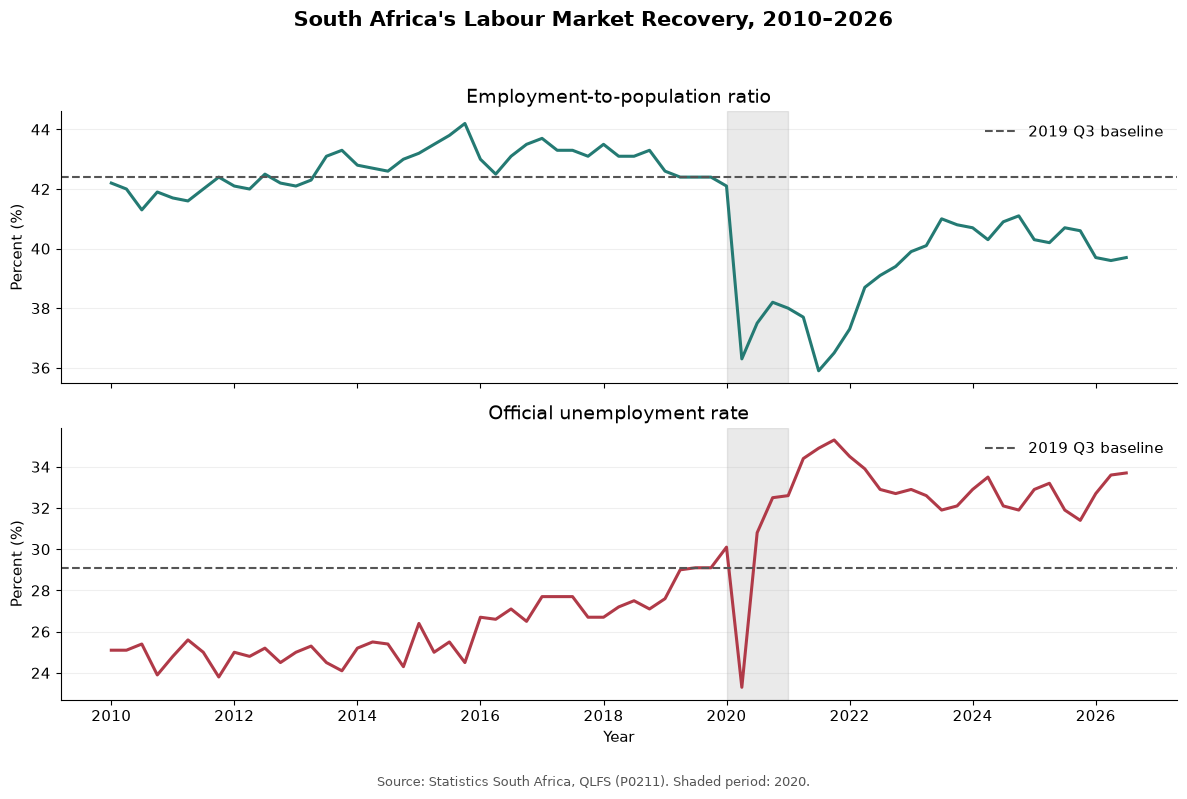

In [33]:
dates = pd.PeriodIndex(
    qlfs["quarter"], freq="Q"
).to_timestamp()

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True
)

labour_charts = [
    (
        "employment_population_ratio_pct",
        "Employment-to-population ratio",
        TEAL
    ),
    (
        "official_unemployment_rate_pct",
        "Official unemployment rate",
        RED
    )
]

for ax, (column, title, color) in zip(axes, labour_charts):

    ax.plot(
        dates,
        qlfs[column],
        color=color,
        linewidth=2.2
    )

    ax.axhline(
        qlfs_baseline[column],
        color=GREY,
        linestyle="--",
        label="2019 Q3 baseline"
    )

    ax.axvspan(
        pd.Timestamp("2020-01-01"),
        pd.Timestamp("2021-01-01"),
        color=GREY,
        alpha=0.12
    )

    ax.set(
        title=title,
        ylabel="Percent (%)"
    )

    ax.legend()
    ax.grid(axis="y", alpha=0.2)

axes[-1].set_xlabel("Year")

fig.suptitle(
    "South Africa's Labour Market Recovery, 2010–2026",
    fontsize=15,
    fontweight="bold"
)

fig.text(
    0.5, 0.01,
    "Source: Statistics South Africa, QLFS (P0211). "
    "Shaded period: 2020.",
    ha="center",
    fontsize=9,
    color=GREY
)

fig.tight_layout(rect=[0, 0.04, 1, 0.95])

fig.savefig(
    FIGURES_DIR / "06_sa_labour_market_recovery.png",
    bbox_inches="tight"
)

plt.show()

### 5.3 Employment recovery benchmark

The employment recovery benchmark estimates how many people
would be employed in 2026 Q3 if the employment-to-population
ratio observed in 2019 Q3 had been maintained.

$$
E_t^* = P_t \times \frac{E_0}{P_0}
$$

The employment shortfall is calculated as:

$$
S_t = E_t^* - E_t
$$

where $E_t^*$ is benchmark employment, $P_t$ is the current
working-age population, and $E_t$ is observed employment.

This benchmark uses underlying population counts rather
than rounded published employment ratios.

In [34]:
baseline_ratio = (
    qlfs_baseline["employed"]
    / qlfs_baseline["working_age_population"]
)

latest_ratio = (
    qlfs_latest["employed"]
    / qlfs_latest["working_age_population"]
)

expected_employment = (
    qlfs_latest["working_age_population"] * baseline_ratio
)

actual_employment = qlfs_latest["employed"]

employment_shortfall = expected_employment - actual_employment

employment_benchmark = pd.DataFrame([{
    "baseline_quarter": "2019Q3",
    "comparison_quarter": "2026Q3",
    "baseline_employment_ratio_pct": baseline_ratio * 100,
    "latest_employment_ratio_pct": latest_ratio * 100,
    "latest_working_age_population": (
        qlfs_latest["working_age_population"]
    ),
    "benchmark_employment": expected_employment,
    "actual_employment": actual_employment,
    "employment_shortfall": employment_shortfall,
    "shortfall_pct_of_benchmark": (
        employment_shortfall / expected_employment * 100
    )
}])

employment_benchmark.to_csv(
    PROCESSED_DIR / "employment_recovery_benchmark.csv",
    index=False
)

employment_benchmark.T.round(3)

,0
baseline_quarter,2019Q3
comparison_quarter,2026Q3
baseline_employment_ratio_pct,42.441815
latest_employment_ratio_pct,39.692167
latest_working_age_population,42426552.989296
benchmark_employment,18006599.039984
actual_employment,16840018.150546
employment_shortfall,1166580.889438
shortfall_pct_of_benchmark,6.47863


#### Interpretation

Between 2019 Q3 and 2026 Q3, employment increased by 2.84%,
while the working-age population increased by 9.96%.

The employment-to-population ratio declined from 42.4%
to 39.7%, and the official unemployment rate increased
from 29.1% to 33.7%.

Maintaining the 2019 Q3 employment ratio would imply
approximately 18.01 million employed people in 2026 Q3,
compared with observed employment of 16.84 million.

The resulting employment shortfall is approximately
1.17 million people relative to this benchmark.

This is a descriptive benchmark, not an estimate of jobs
lost due to the pandemic, existing vacancies or the causal
effect of economic policy.

## 6. Consumer prices and inflation

Monthly Consumer Price Index (CPI) data are obtained from
Statistics South Africa's P0141 historical time-series workbook.

The analysis uses headline CPI for all urban areas, with
December 2024 as the index reference period.

Monthly observations cover January 2010 to October 2026.

Consumer price growth is assessed relative to October 2019,
allowing comparison between the same calendar months.

In [37]:
raw_cpi = pd.read_excel(
    cpi_file,
    sheet_name="Excel table from 2008",
    header=None
)

headline_rows = raw_cpi.loc[
    raw_cpi[2].astype(str).str.strip().eq("CPS00000")
    & raw_cpi[3].astype(str).str.strip().eq("CPI Headline")
]

assert len(headline_rows) == 1

headline = headline_rows.iloc[0]

headers = raw_cpi.iloc[0].astype(str).str.strip()

monthly_headers = headers[
    headers.str.fullmatch(r"MO\d{6}")
]

cpi = pd.DataFrame({
    "date": pd.to_datetime(
        monthly_headers.str[2:],
        format="%m%Y"
    ),
    "headline_cpi": pd.to_numeric(
        headline.loc[monthly_headers.index],
        errors="coerce"
    )
})

cpi = (
    cpi.loc[cpi["date"].between("2010-01-01", "2026-10-01")]
    .sort_values("date")
    .reset_index(drop=True)
)

cpi.insert(1, "year", cpi["date"].dt.year)
cpi.insert(2, "month", cpi["date"].dt.month)

cpi.head()

,date,year,month,headline_cpi
0,2010-01-01,2010,1,48.1
1,2010-02-01,2010,2,48.4
2,2010-03-01,2010,3,48.8
3,2010-04-01,2010,4,48.8
4,2010-05-01,2010,5,48.9


In [38]:
raw_cpi = pd.read_excel(
    cpi_file,
    sheet_name="Excel table from 2008",
    header=None
)

headline_rows = raw_cpi.loc[
    raw_cpi[2].astype(str).str.strip().eq("CPS00000")
    & raw_cpi[3].astype(str).str.strip().eq("CPI Headline")
]

assert len(headline_rows) == 1

headline = headline_rows.iloc[0]

headers = raw_cpi.iloc[0].astype(str).str.strip()

monthly_headers = headers[
    headers.str.fullmatch(r"MO\d{6}")
]

cpi = pd.DataFrame({
    "date": pd.to_datetime(
        monthly_headers.str[2:],
        format="%m%Y"
    ),
    "headline_cpi": pd.to_numeric(
        headline.loc[monthly_headers.index],
        errors="coerce"
    )
})

cpi = (
    cpi.loc[cpi["date"].between("2010-01-01", "2026-10-01")]
    .sort_values("date")
    .reset_index(drop=True)
)

cpi.insert(1, "year", cpi["date"].dt.year)
cpi.insert(2, "month", cpi["date"].dt.month)

cpi.head()

,date,year,month,headline_cpi
0,2010-01-01,2010,1,48.1
1,2010-02-01,2010,2,48.4
2,2010-03-01,2010,3,48.8
3,2010-04-01,2010,4,48.8
4,2010-05-01,2010,5,48.9


In [39]:
cpi["inflation_mom_pct"] = (
    cpi["headline_cpi"].pct_change(fill_method=None) * 100
)

cpi["inflation_yoy_pct"] = (
    cpi["headline_cpi"].pct_change(12, fill_method=None) * 100
)

cpi.tail().round(3)

C:\Users\shadr\AppData\Local\Temp\ipykernel_20148\1968816472.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  cpi.tail().round(3)


,date,year,month,headline_cpi,inflation_mom_pct,inflation_yoy_pct
197,2026-06-01,2026,6,107.5,0.750,4.980
198,2026-07-01,2026,7,107.7,0.186,4.259
199,2026-08-01,2026,8,107.7,0.000,4.360
200,2026-09-01,2026,9,108.1,0.371,4.545
201,2026-10-01,2026,10,108.9,0.740,5.217


In [40]:
expected_months = pd.date_range(
    "2010-01-01",
    "2026-10-01",
    freq="MS"
)

assert cpi["date"].tolist() == expected_months.tolist()
assert cpi["headline_cpi"].notna().all()
assert cpi["headline_cpi"].gt(0).all()

assert cpi["inflation_mom_pct"].isna().sum() == 1
assert cpi["inflation_yoy_pct"].isna().sum() == 12

cpi.to_csv(
    PROCESSED_DIR / "south_africa_headline_cpi_monthly_2010_2026.csv",
    index=False
)

cpi.info()

<class 'pandas.DataFrame'>
RangeIndex: 202 entries, 0 to 201
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   date               202 non-null    datetime64[us]
 1   year               202 non-null    int32         
 2   month              202 non-null    int32         
 3   headline_cpi       202 non-null    float64       
 4   inflation_mom_pct  201 non-null    float64       
 5   inflation_yoy_pct  190 non-null    float64       
dtypes: datetime64[us](1), float64(3), int32(2)
memory usage: 8.0 KB


### 6.1 Cumulative consumer price growth

Cumulative consumer price growth is calculated as:

$$
\Delta CPI = \left(\frac{CPI_t}{CPI_0}-1\right)\times100
$$

Unlike the annual inflation rate, cumulative price growth
measures the total change in the consumer price level
over the entire comparison period.

An illustrative consumer basket costing R1,000 in October
2019 is used to express this change in monetary terms.

In [41]:
cpi_oct_2019 = cpi.loc[
    cpi["date"] == "2019-10-01",
    "headline_cpi"
].item()

cpi_oct_2026 = cpi.loc[
    cpi["date"] == "2026-10-01",
    "headline_cpi"
].item()

cumulative_inflation = (
    cpi_oct_2026 / cpi_oct_2019 - 1
) * 100

basket_2019 = 1000

basket_2026 = (
    basket_2019 * cpi_oct_2026 / cpi_oct_2019
)

price_comparison = pd.Series({
    "October 2019 CPI": cpi_oct_2019,
    "October 2026 CPI": cpi_oct_2026,
    "Cumulative price growth (%)": cumulative_inflation,
    "Baseline basket cost (R)": basket_2019,
    "Equivalent 2026 basket cost (R)": basket_2026
})

price_comparison.round(2)

October 2019 CPI                     78.60
October 2026 CPI                    108.90
Cumulative price growth (%)          38.55
Baseline basket cost (R)           1000.00
Equivalent 2026 basket cost (R)    1385.50
dtype: float64

### 6.2 Annual average consumer prices

Annual average CPI is calculated from the available monthly
observations within each calendar year.

The annual series is indexed to 2019 to illustrate changes
in average consumer price levels.

The 2026 observations cover January to October only.
Consequently, the 2026 average is not directly comparable
with complete calendar-year averages.

In [42]:
annual_cpi = (
    cpi.groupby("year", as_index=False)
    .agg(
        average_cpi=("headline_cpi", "mean"),
        months_observed=("headline_cpi", "count")
    )
)

annual_cpi_2019 = annual_cpi.loc[
    annual_cpi["year"] == 2019,
    "average_cpi"
].item()

annual_cpi["price_index_2019"] = (
    annual_cpi["average_cpi"] / annual_cpi_2019 * 100
)

annual_cpi["annual_average_inflation_pct"] = (
    annual_cpi["average_cpi"].pct_change(fill_method=None) * 100
)

assert len(annual_cpi) == 17

assert annual_cpi.loc[
    annual_cpi["year"] < 2026,
    "months_observed"
].eq(12).all()

assert annual_cpi.loc[
    annual_cpi["year"] == 2026,
    "months_observed"
].item() == 10

annual_cpi.to_csv(
    PROCESSED_DIR / "south_africa_annual_cpi_2010_2026.csv",
    index=False
)

annual_cpi.round(2)

,year,average_cpi,months_observed,price_index_2019,annual_average_inflation_pct
0,2010,49.02,12,63.01,NaN
1,2011,51.47,12,66.15,4.98
2,2012,54.38,12,69.89,5.65
3,2013,57.50,12,73.91,5.75
4,2014,61.02,12,78.43,6.12
5,2015,63.82,12,82.03,4.59
6,2016,67.85,12,87.21,6.32
7,2017,71.44,12,91.83,5.29
8,2018,74.72,12,96.05,4.60
9,2019,77.80,12,100.00,4.12


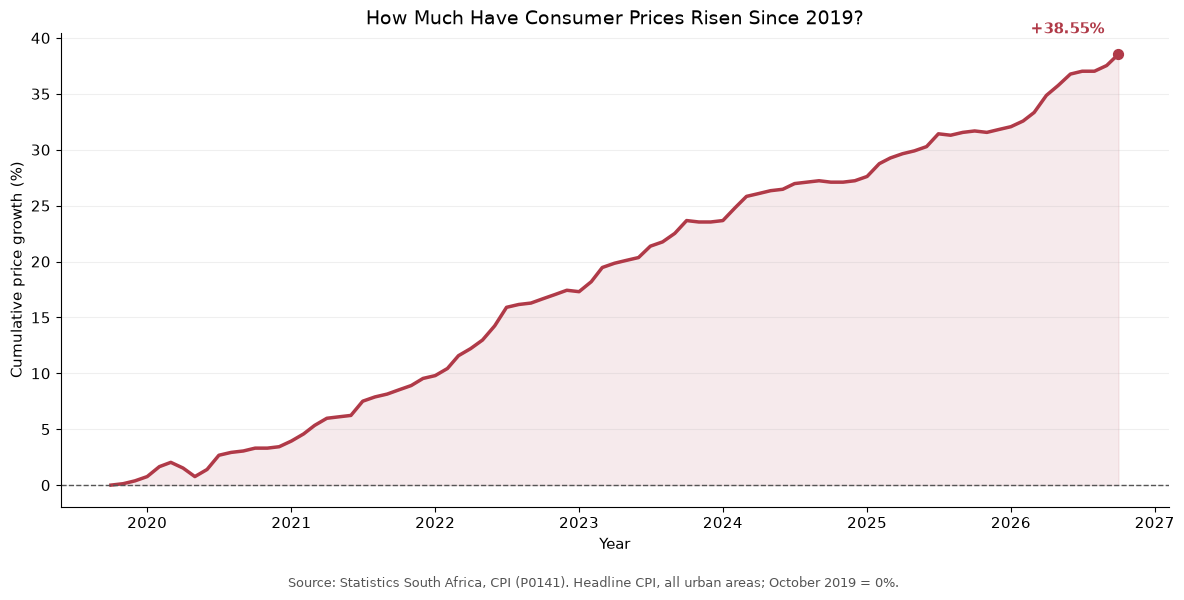

In [43]:
plot_cpi = cpi.loc[
    cpi["date"] >= "2019-10-01"
].copy()

plot_cpi["cumulative_inflation_pct"] = (
    plot_cpi["headline_cpi"] / cpi_oct_2019 - 1
) * 100

fig, ax = plt.subplots()

ax.plot(
    plot_cpi["date"],
    plot_cpi["cumulative_inflation_pct"],
    color=RED,
    linewidth=2.5
)

ax.fill_between(
    plot_cpi["date"],
    0,
    plot_cpi["cumulative_inflation_pct"],
    color=RED,
    alpha=0.10
)

ax.axhline(
    0,
    color=GREY,
    linestyle="--",
    linewidth=1
)

last = plot_cpi.iloc[-1]

ax.scatter(
    last["date"],
    last["cumulative_inflation_pct"],
    color=RED,
    s=50,
    zorder=5
)

ax.annotate(
    f"{cumulative_inflation:+.2f}%",
    xy=(
        last["date"],
        last["cumulative_inflation_pct"]
    ),
    xytext=(-10, 15),
    textcoords="offset points",
    ha="right",
    fontweight="bold",
    color=RED
)

ax.set(
    title="How Much Have Consumer Prices Risen Since 2019?",
    xlabel="Year",
    ylabel="Cumulative price growth (%)"
)

ax.grid(axis="y", alpha=0.2)

fig.text(
    0.5, 0.01,
    "Source: Statistics South Africa, CPI (P0141). "
    "Headline CPI, all urban areas; October 2019 = 0%.",
    ha="center",
    fontsize=9,
    color=GREY
)

fig.tight_layout(rect=[0, 0.04, 1, 1])

fig.savefig(
    FIGURES_DIR / "07_cumulative_consumer_price_increase.png",
    bbox_inches="tight"
)

plt.show()

#### Interpretation

Between October 2019 and October 2026, headline CPI increased
from 78.6 to 108.9, representing a cumulative consumer price
increase of 38.55%.

An illustrative consumer basket costing R1,000 in October
2019 would therefore cost approximately R1,385.50 in
October 2026.

A decline in the inflation rate does not necessarily imply
a decline in consumer prices. Positive inflation indicates
that prices continue to increase, even when the rate of
increase slows.

Headline CPI represents an aggregate consumer basket.
Individual households may experience different price
changes depending on their expenditure patterns.

## 7. Real earnings and purchasing power

Average monthly earnings are obtained from Statistics South
Africa's Quarterly Employment Statistics (QES) publications.

The comparison uses two reference months:

| Reference month | Average monthly earnings | Publication |
|---|---:|---|
| November 2019 | R22,500 | P0277, December 2019, Table G |
| May 2026 | R30,611 | P0277, June 2026, Table H |

The QES covers the formal non-agricultural sector.

Nominal earnings are adjusted using headline CPI for the
corresponding reference months to assess changes in average
purchasing power.

In [44]:
earnings = pd.DataFrame({
    "date": pd.to_datetime([
        "2019-11-01",
        "2026-05-01"
    ]),
    "nominal_earnings": [
        22500,
        30611
    ]
})

earnings = earnings.merge(
    cpi[["date", "headline_cpi"]],
    on="date",
    how="left",
    validate="one_to_one"
)

assert earnings["headline_cpi"].notna().all()

earnings

,date,nominal_earnings,headline_cpi
0,2019-11-01,22500,78.7
1,2026-05-01,30611,106.7


### 7.1 Inflation-adjusted earnings

Nominal earnings are converted into November 2019 purchasing
power using:

$$
W_t^{real} = W_t^{nominal}\frac{CPI_0}{CPI_t}
$$

Real earnings growth is calculated as:

$$
g_{real} =
\left(
\frac{W_t^{real}}{W_0^{nominal}}-1
\right)\times100
$$

This adjustment separates changes in nominal earnings from
changes in the general consumer price level.

In [45]:
baseline_earnings = earnings.iloc[0]
latest_earnings = earnings.iloc[1]

earnings_2019 = baseline_earnings["nominal_earnings"]
earnings_2026 = latest_earnings["nominal_earnings"]

cpi_2019 = baseline_earnings["headline_cpi"]
cpi_2026 = latest_earnings["headline_cpi"]

earnings["real_earnings"] = (
    earnings["nominal_earnings"] * cpi_2019
    / earnings["headline_cpi"]
)

nominal_growth = (
    earnings_2026 / earnings_2019 - 1
) * 100

price_growth = (
    cpi_2026 / cpi_2019 - 1
) * 100

earnings_2026_in_2019_rands = (
    earnings["real_earnings"].iloc[-1]
)

real_growth = (
    earnings_2026_in_2019_rands / earnings_2019 - 1
) * 100

earnings.round(2)

C:\Users\shadr\AppData\Local\Temp\ipykernel_20148\1789797961.py:31: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  earnings.round(2)


,date,nominal_earnings,headline_cpi,real_earnings
0,2019-11-01,22500,78.7,22500.00
1,2026-05-01,30611,106.7,22578.12


In [46]:
earnings_recovery = pd.DataFrame([{
    "baseline_month": "2019-11",
    "comparison_month": "2026-05",
    "nominal_earnings_2019": earnings_2019,
    "nominal_earnings_2026": earnings_2026,
    "cpi_2019": cpi_2019,
    "cpi_2026": cpi_2026,
    "nominal_growth_pct": nominal_growth,
    "consumer_price_growth_pct": price_growth,
    "real_earnings_growth_pct": real_growth,
    "earnings_2026_in_2019_rands": (
        earnings_2026_in_2019_rands
    )
}])

earnings_recovery.to_csv(
    PROCESSED_DIR / "sa_real_earnings_recovery.csv",
    index=False
)

earnings_recovery.T.round(2)

,0
baseline_month,2019-11
comparison_month,2026-05
nominal_earnings_2019,22500
nominal_earnings_2026,30611
cpi_2019,78.7
cpi_2026,106.7
nominal_growth_pct,36.048889
consumer_price_growth_pct,35.578145
real_earnings_growth_pct,0.347212
earnings_2026_in_2019_rands,22578.122774


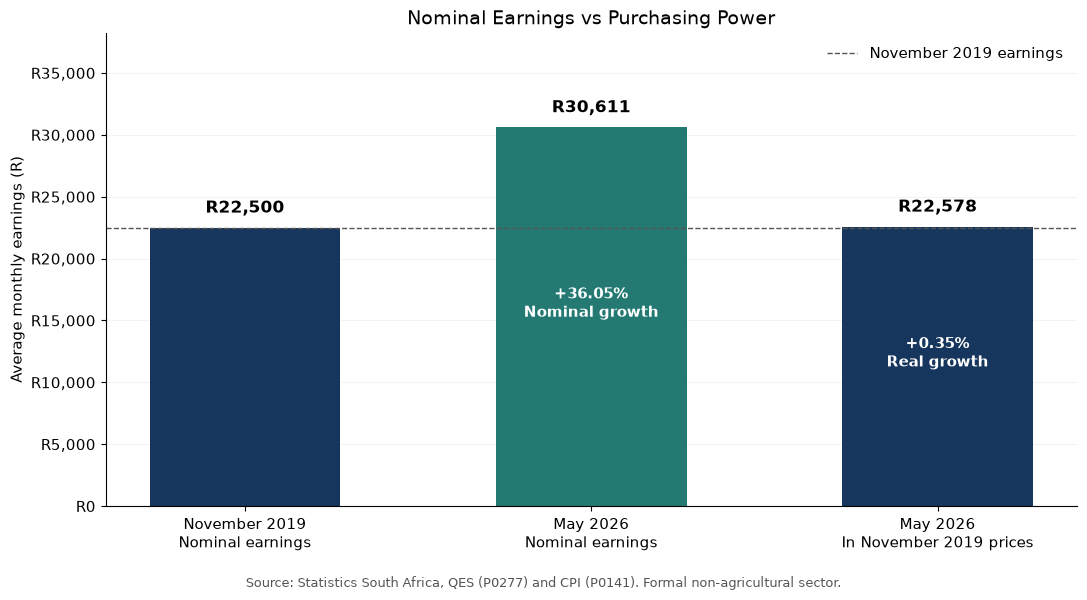

In [47]:
labels = [
    "November 2019\nNominal earnings",
    "May 2026\nNominal earnings",
    "May 2026\nIn November 2019 prices"
]

values = [
    earnings_2019,
    earnings_2026,
    earnings_2026_in_2019_rands
]

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    labels,
    values,
    color=[NAVY, TEAL, NAVY],
    width=0.55
)

ax.bar_label(
    bars,
    labels=[f"R{value:,.0f}" for value in values],
    padding=8,
    fontsize=12,
    fontweight="bold"
)

ax.axhline(
    earnings_2019,
    color=GREY,
    linestyle="--",
    linewidth=1,
    label="November 2019 earnings"
)

ax.set(
    title="Nominal Earnings vs Purchasing Power",
    ylabel="Average monthly earnings (R)",
    ylim=(0, max(values) * 1.25)
)

ax.text(
    1,
    earnings_2026 / 2,
    f"{nominal_growth:+.2f}%\nNominal growth",
    ha="center",
    color="white",
    fontweight="bold"
)

ax.text(
    2,
    earnings_2026_in_2019_rands / 2,
    f"{real_growth:+.2f}%\nReal growth",
    ha="center",
    color="white",
    fontweight="bold"
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"R{value:,.0f}")
)

ax.legend()
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

fig.text(
    0.5, 0.01,
    "Source: Statistics South Africa, QES (P0277) and CPI (P0141). "
    "Formal non-agricultural sector.",
    ha="center",
    fontsize=9,
    color=GREY
)

fig.tight_layout(rect=[0, 0.04, 1, 1])

fig.savefig(
    FIGURES_DIR / "08_nominal_vs_real_earnings.png",
    bbox_inches="tight"
)

plt.show()

#### Interpretation

Average monthly earnings increased from R22,500 in November
2019 to R30,611 in May 2026, representing nominal growth
of 36.05%.

Over the same period, consumer prices increased by 35.58%.

After adjusting for inflation, May 2026 average monthly
earnings were equivalent to approximately R22,578 in
November 2019 purchasing power.

Real average monthly earnings therefore increased by
only 0.35%, indicating that average purchasing power
was broadly unchanged between the two observations.

This comparison has several limitations. The QES covers
formal non-agricultural employment rather than the entire
labour market. Average earnings may also be influenced
by workforce composition, overtime, bonuses and seasonal
differences between the reference months.

The comparison does not measure individual wage growth,
median earnings or household disposable income. Two
observations are insufficient to establish a long-term
earnings trend or statistical significance.

## 8. Economic recovery scorecard

South Africa's economic recovery is assessed across five
dimensions:

- Economic output
- Living standards
- Labour-market recovery
- Consumer prices
- Purchasing power

Each dimension captures a different aspect of economic
performance relative to its pre-pandemic reference period.

The indicators are presented separately rather than combined
into a composite index because they differ in measurement,
units, reference periods and economic interpretation.

In [48]:
scorecard = pd.DataFrame([
    {
        "dimension": "Economic Output",
        "indicator": "Real GDP",
        "baseline": "2019 Q4",
        "latest": "2026 Q2",
        "change": gdp_recovery_pct,
        "unit": "%",
        "interpretation": (
            "Aggregate output above pre-pandemic level"
        )
    },
    {
        "dimension": "Living Standards",
        "indicator": "Real GDP per Capita",
        "baseline": "2019",
        "latest": "2025",
        "change": gdp_pc_growth_pct,
        "unit": "%",
        "interpretation": (
            "Real output per person remains below 2019"
        )
    },
    {
        "dimension": "Labour Market",
        "indicator": "Employment-to-Population Ratio",
        "baseline": "2019 Q3",
        "latest": "2026 Q3",
        "change": employment_ratio_change,
        "unit": "percentage points",
        "interpretation": (
            "Smaller share of working-age population employed"
        )
    },
    {
        "dimension": "Consumer Prices",
        "indicator": "Headline CPI",
        "baseline": "October 2019",
        "latest": "October 2026",
        "change": cumulative_inflation,
        "unit": "%",
        "interpretation": (
            "Consumer price level substantially higher"
        )
    },
    {
        "dimension": "Purchasing Power",
        "indicator": "Real Average Monthly Earnings",
        "baseline": "November 2019",
        "latest": "May 2026",
        "change": real_growth,
        "unit": "%",
        "interpretation": (
            "Average formal-sector real earnings nearly stagnant"
        )
    }
])

scorecard["change"] = scorecard["change"].round(2)

scorecard

,dimension,indicator,baseline,latest,change,unit,interpretation
0,Economic Output,Real GDP,2019 Q4,2026 Q2,2.24,%,Aggregate output above pre-pandemic level
1,Living Standards,Real GDP per Capita,2019,2025,-5.36,%,Real output per person remains below 2019
2,Labour Market,Employment-to-Population Ratio,2019 Q3,2026 Q3,-2.70,percentage points,Smaller share of working-age population employed
3,Consumer Prices,Headline CPI,October 2019,October 2026,38.55,%,Consumer price level substantially higher
4,Purchasing Power,Real Average Monthly Earnings,November 2019,May 2026,0.35,%,Average formal-sector real earnings nearly sta...


In [49]:
assert len(scorecard) == 5
assert scorecard["dimension"].is_unique
assert scorecard["indicator"].is_unique
assert scorecard.notna().all().all()
assert np.isfinite(scorecard["change"]).all()

scorecard.to_csv(
    PROCESSED_DIR / "sa_economic_recovery_scorecard.csv",
    index=False
)

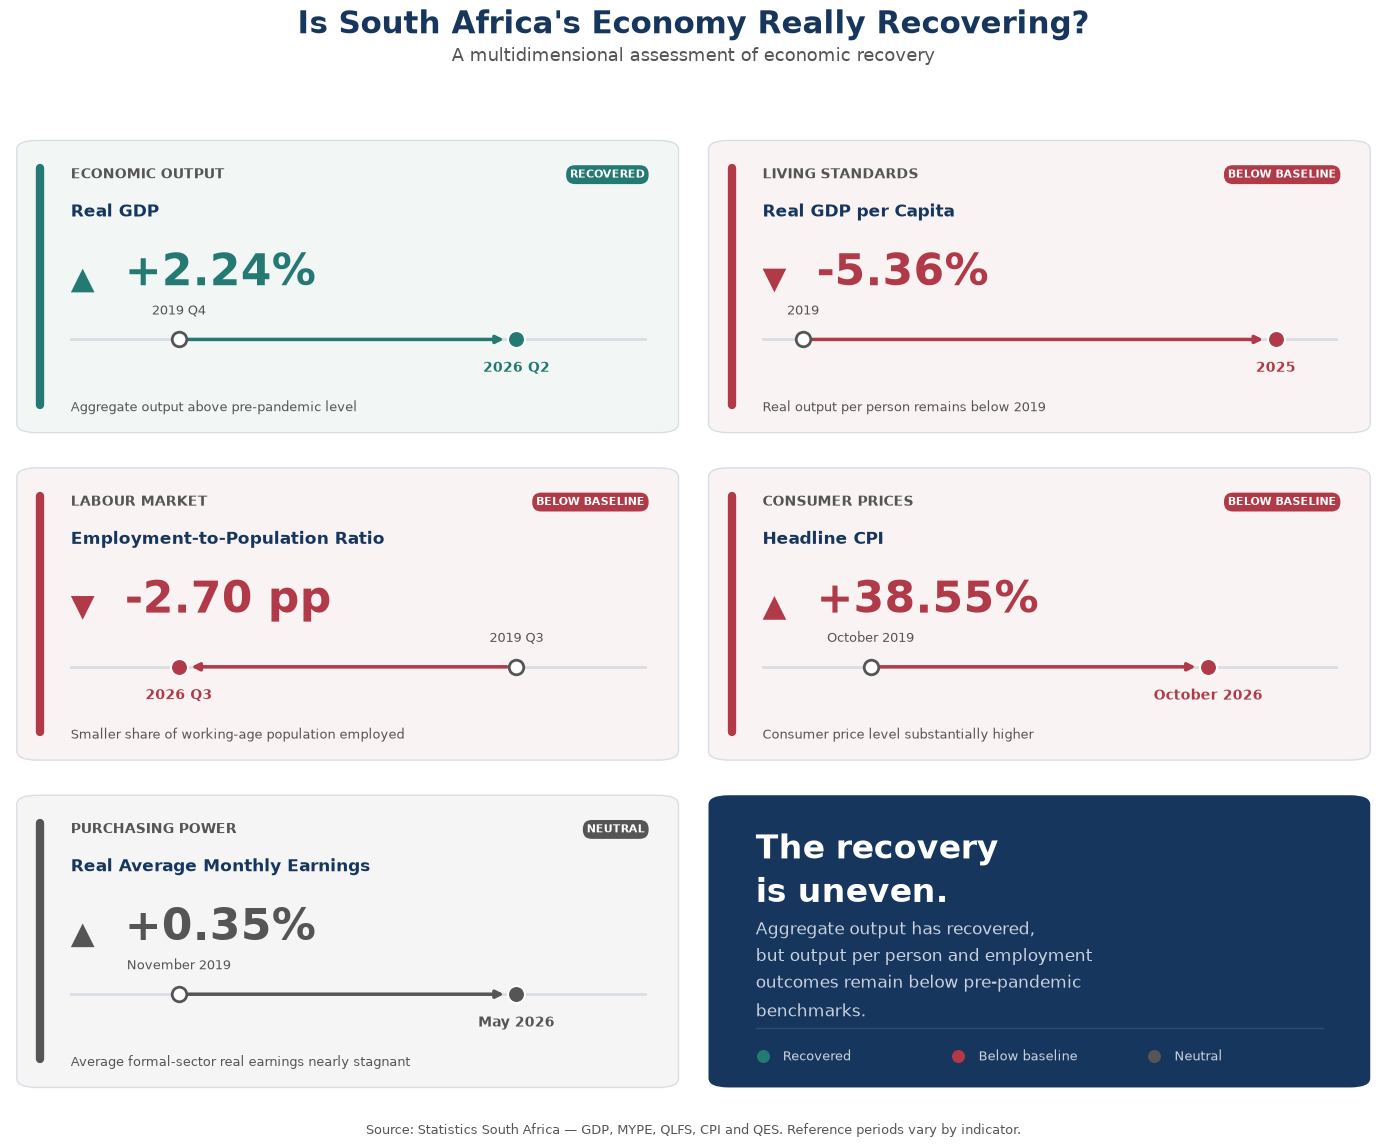

In [53]:
import textwrap
from matplotlib.patches import FancyBboxPatch

LIGHT_BORDER = "#D9DEE5"
status_labels = ["RECOVERED", "BELOW BASELINE", "BELOW BASELINE",
                 "BELOW BASELINE", "NEUTRAL"]
colors = [TEAL, RED, RED, RED, GREY]


def to_num(x):
    try:
        return float(str(x).replace("%", "").replace(",", "").strip())
    except ValueError:
        return None


fig, axes = plt.subplots(3, 2, figsize=(14, 11.5))
axes = axes.flatten()

for ax, (_, row), color, status in zip(
    axes, scorecard.iterrows(), colors, status_labels
):
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    # Card background, softly tinted with the status colour
    ax.add_patch(FancyBboxPatch(
        (0.02, 0.04), 0.96, 0.92,
        boxstyle="round,pad=0.01,rounding_size=0.03",
        facecolor=color, alpha=0.06, edgecolor="none"
    ))
    ax.add_patch(FancyBboxPatch(
        (0.02, 0.04), 0.96, 0.92,
        boxstyle="round,pad=0.01,rounding_size=0.03",
        facecolor="none", edgecolor=LIGHT_BORDER, linewidth=1
    ))

    # Accent bar on the left
    ax.plot([0.045, 0.045], [0.12, 0.88], color=color, lw=6,
            solid_capstyle="round")

    # Header: dimension + status pill
    ax.text(0.09, 0.86, row["dimension"].upper(),
            fontsize=10, fontweight="bold", color=GREY, va="center")
    ax.text(0.94, 0.86, status, fontsize=8, fontweight="bold",
            color="white", ha="right", va="center",
            bbox=dict(boxstyle="round,pad=0.35,rounding_size=0.8",
                      facecolor=color, edgecolor="none"))

    ax.text(0.09, 0.74, row["indicator"],
            fontsize=12.5, fontweight="bold", color=NAVY, va="center")

    # Big number with direction arrow
    unit = "%" if row["unit"] == "%" else " pp"
    arrow = "▲" if row["change"] > 0 else "▼" if row["change"] < 0 else "●"
    ax.text(0.09, 0.47, arrow, fontsize=22, color=color, va="bottom")
    ax.text(0.17, 0.47, f"{row['change']:+.2f}{unit}",
            fontsize=32, fontweight="bold", color=color, va="bottom")

    # Mini baseline -> latest track
    y = 0.33
    b, l = to_num(row["baseline"]), to_num(row["latest"])
    if b is not None and l is not None and b != l:
        lo, hi = min(b, l), max(b, l)
        xb = 0.15 + 0.70 * (b - lo) / (hi - lo)
        xl = 0.15 + 0.70 * (l - lo) / (hi - lo)
    else:
        xb, xl = (0.25, 0.75) if row["change"] >= 0 else (0.75, 0.25)

    ax.plot([0.09, 0.94], [y, y], color=LIGHT_BORDER, lw=2, zorder=1)
    ax.annotate("", xy=(xl, y), xytext=(xb, y),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2.5,
                                shrinkA=7, shrinkB=9), zorder=2)
    ax.scatter([xb], [y], s=110, facecolor="white", edgecolor=GREY,
               linewidth=2, zorder=3)
    ax.scatter([xl], [y], s=150, facecolor=color, edgecolor="white",
               linewidth=1.5, zorder=3)

    ax.text(xb, y + 0.07, f"{row['baseline']}", ha="center",
            fontsize=9.5, color=GREY, va="bottom")
    ax.text(xl, y - 0.07, f"{row['latest']}", ha="center",
            fontsize=10, fontweight="bold", color=color, va="top")

    # Interpretation
    ax.text(0.09, 0.14, textwrap.fill(row["interpretation"], 70),
            fontsize=9, color=GREY, va="top", linespacing=1.4)

# ── Summary tile: dark panel to anchor the grid ──
ax = axes[-1]
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
ax.add_patch(FancyBboxPatch(
    (0.02, 0.04), 0.96, 0.92,
    boxstyle="round,pad=0.01,rounding_size=0.03",
    facecolor=NAVY, edgecolor="none"
))

ax.text(0.08, 0.86, "The recovery\nis uneven.",
        fontsize=24, fontweight="bold", color="white",
        va="top", linespacing=1.2)

ax.text(0.08, 0.58,
        "Aggregate output has recovered,\n"
        "but output per person and employment\n"
        "outcomes remain below pre-pandemic\n"
        "benchmarks.",
        fontsize=12, color="#C9D3E0", linespacing=1.6, va="top")

# Divider + legend, kept well clear of the body text
ax.plot([0.08, 0.92], [0.22, 0.22], color="#2C4A72", lw=1)

legend_items = [(TEAL, "Recovered"),
                (RED, "Below baseline"),
                (GREY, "Neutral")]
for i, (c, label) in enumerate(legend_items):
    x = 0.09 + i * 0.29
    ax.scatter([x], [0.13], s=70, color=c, zorder=3)
    ax.text(x + 0.03, 0.13, label, fontsize=9,
            color="#C9D3E0", va="center")

# ── Titles and layout ──
fig.suptitle("Is South Africa's Economy Really Recovering?",
             fontsize=22, fontweight="bold", color=NAVY, y=0.99)
fig.text(0.5, 0.945, "A multidimensional assessment of economic recovery",
         ha="center", fontsize=13, color=GREY)
fig.text(0.5, 0.012,
         "Source: Statistics South Africa — GDP, MYPE, QLFS, CPI and QES. "
         "Reference periods vary by indicator.",
         ha="center", fontsize=9, color=GREY)

fig.tight_layout(rect=[0, 0.03, 1, 0.94])
fig.savefig(FIGURES_DIR / "09_sa_economic_recovery_scorecard.png",
            dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

### 8.1 Assessment of economic recovery

The indicators reveal an uneven recovery across South
Africa's economy.

Aggregate real GDP exceeded its pre-pandemic level by 2.24%.
However, real GDP per capita remained 5.36% below its 2019
level, indicating that economic output had not kept pace
with population growth.

Labour-market recovery was similarly incomplete, with the
employment-to-population ratio declining by 2.7 percentage
points relative to 2019 Q3.

Consumer prices increased substantially, while average
inflation-adjusted earnings in the formal non-agricultural
sector remained broadly unchanged between the selected
reference months.

Taken together, these findings suggest that recovery in
aggregate economic output has not been accompanied by
comparable improvements in output per person, employment
outcomes and average purchasing power.

The scorecard is descriptive and does not establish causal
relationships between the indicators.

## 9. Data quality and reproducibility

The final validation stage evaluates the integrity of the
processed datasets and the reproducibility of the analytical
results.

Validation includes dataset dimensions, duplicate records,
missing values, numerical consistency, statistical estimates
and the availability of generated visualisations.

Previously established analytical results are used as
reference values for regression testing.

In [54]:
expected_datasets = {
    "south_africa_real_gdp_quarterly.csv": (66, 0),
    "gdp_trend_sensitivity.csv": (3, 0),
    "south_africa_population_2010_2026.csv": (17, 0),
    "sa_real_gdp_per_capita_2010_2025.csv": (16, 0),
    "south_africa_qlfs_quarterly_2010_2026.csv": (67, 0),
    "qlfs_recovery_comparison.csv": (6, 0),
    "employment_recovery_benchmark.csv": (1, 0),
    "south_africa_headline_cpi_monthly_2010_2026.csv": (202, 13),
    "south_africa_annual_cpi_2010_2026.csv": (17, 1),
    "sa_real_earnings_recovery.csv": (1, 0),
    "sa_economic_recovery_scorecard.csv": (5, 0)
}

In [55]:
dataset_audit = []

for filename, (expected_rows, expected_nulls) in expected_datasets.items():

    path = PROCESSED_DIR / filename
    data = pd.read_csv(path)

    rows = len(data)
    duplicates = data.duplicated().sum()
    missing = data.isna().sum().sum()

    passed = (
        rows == expected_rows
        and duplicates == 0
        and missing == expected_nulls
    )

    dataset_audit.append({
        "dataset": filename,
        "rows": rows,
        "expected_rows": expected_rows,
        "columns": data.shape[1],
        "duplicates": duplicates,
        "missing_values": missing,
        "expected_missing": expected_nulls,
        "status": "PASS" if passed else "FAIL"
    })

dataset_audit = pd.DataFrame(dataset_audit)

dataset_audit

,dataset,rows,expected_rows,columns,duplicates,missing_values,expected_missing,status
0,south_africa_real_gdp_quarterly.csv,66,66,5,0,0,0,PASS
1,gdp_trend_sensitivity.csv,3,3,8,0,0,0,PASS
2,south_africa_population_2010_2026.csv,17,17,3,0,0,0,PASS
3,sa_real_gdp_per_capita_2010_2025.csv,16,16,5,0,0,0,PASS
4,south_africa_qlfs_quarterly_2010_2026.csv,67,67,16,0,0,0,PASS
5,qlfs_recovery_comparison.csv,6,6,5,0,0,0,PASS
6,employment_recovery_benchmark.csv,1,1,9,0,0,0,PASS
7,south_africa_headline_cpi_monthly_2010_2026.csv,202,202,6,0,13,13,PASS
8,south_africa_annual_cpi_2010_2026.csv,17,17,5,0,1,1,PASS
9,sa_real_earnings_recovery.csv,1,1,10,0,0,0,PASS


In [56]:
monthly_cpi_export = pd.read_csv(
    PROCESSED_DIR / "south_africa_headline_cpi_monthly_2010_2026.csv"
)

annual_cpi_export = pd.read_csv(
    PROCESSED_DIR / "south_africa_annual_cpi_2010_2026.csv"
)

assert monthly_cpi_export["inflation_mom_pct"].iloc[:1].isna().all()
assert monthly_cpi_export["inflation_mom_pct"].iloc[1:].notna().all()

assert monthly_cpi_export["inflation_yoy_pct"].iloc[:12].isna().all()
assert monthly_cpi_export["inflation_yoy_pct"].iloc[12:].notna().all()

assert annual_cpi_export["annual_average_inflation_pct"].iloc[:1].isna().all()
assert annual_cpi_export["annual_average_inflation_pct"].iloc[1:].notna().all()

assert dataset_audit["status"].eq("PASS").all()

pd.Series({
    "Datasets validated": len(dataset_audit),
    "Total observations": dataset_audit["rows"].sum(),
    "Duplicate records": dataset_audit["duplicates"].sum(),
    "Structural missing values": dataset_audit["missing_values"].sum(),
    "Datasets passed": dataset_audit["status"].eq("PASS").sum()
})

Datasets validated            11
Total observations           401
Duplicate records              0
Structural missing values     14
Datasets passed               11
dtype: int64

### 9.1 Numerical reproducibility

Key analytical results are compared with previously
established reference values.

Absolute tolerances are used to accommodate minor
floating-point and rounding differences.

Percentage-based indicators are evaluated using a tolerance
of 0.01 percentage points, monetary values using R0.01,
and population counts using one person.

In [57]:
saved_benchmark = pd.read_csv(
    PROCESSED_DIR / "employment_recovery_benchmark.csv"
)

numerical_checks = [
    ("Real GDP recovery (%)",
     gdp_recovery_pct, 2.2394, 0.01),

    ("Real GDP per capita growth (%)",
     gdp_pc_growth_pct, -5.3566, 0.01),

    ("Annual real GDP growth (%)",
     annual_gdp_growth_pct, 1.5946, 0.01),

    ("Population growth (%)",
     population_growth_pct, 7.3446, 0.01),

    ("Employment growth (%)",
     employment_growth_pct, 2.8398, 0.01),

    ("Unemployed population growth (%)",
     unemployment_growth_pct, 27.3908, 0.01),

    ("Working-age population growth (%)",
     working_age_growth_pct, 9.9639, 0.01),

    ("Unemployment rate change (pp)",
     unemployment_rate_change, 4.6000, 0.01),

    ("Employment ratio change (pp)",
     employment_ratio_change, -2.7000, 0.01),

    ("Employment benchmark shortfall",
     employment_shortfall, 1166580.8894, 1),

    ("Saved employment shortfall",
     saved_benchmark["employment_shortfall"].item(),
     employment_shortfall, 1),

    ("Cumulative consumer price growth (%)",
     cumulative_inflation, 38.5496, 0.01),

    ("Equivalent R1000 consumer basket",
     basket_2026, 1385.4962, 0.01),

    ("Nominal earnings growth (%)",
     nominal_growth, 36.0489, 0.01),

    ("Earnings-period CPI growth (%)",
     price_growth, 35.5781, 0.01),

    ("Real earnings growth (%)",
     real_growth, 0.3472, 0.01),

    ("Real earnings in November 2019 rands",
     earnings_2026_in_2019_rands, 22578.1228, 0.01)
]

In [58]:
def validate_results(checks):

    results = pd.DataFrame(
        checks,
        columns=[
            "indicator",
            "actual",
            "expected",
            "tolerance"
        ]
    )

    results["absolute_difference"] = (
        results["actual"] - results["expected"]
    ).abs()

    results["status"] = np.where(
        np.isclose(
            results["actual"],
            results["expected"],
            atol=results["tolerance"],
            rtol=0
        ),
        "PASS",
        "FAIL"
    )

    return results

numerical_validation = validate_results(numerical_checks)

numerical_validation.round(4)

,indicator,actual,expected,tolerance,absolute_difference,status
0,Real GDP recovery (%),2.239400e+00,2.239400e+00,0.01,0.0,PASS
1,Real GDP per capita growth (%),-5.356600e+00,-5.356600e+00,0.01,0.0,PASS
2,Annual real GDP growth (%),1.594600e+00,1.594600e+00,0.01,0.0,PASS
3,Population growth (%),7.344600e+00,7.344600e+00,0.01,0.0,PASS
4,Employment growth (%),2.839800e+00,2.839800e+00,0.01,0.0,PASS
5,Unemployed population growth (%),2.739080e+01,2.739080e+01,0.01,0.0,PASS
6,Working-age population growth (%),9.963900e+00,9.963900e+00,0.01,0.0,PASS
7,Unemployment rate change (pp),4.600000e+00,4.600000e+00,0.01,0.0,PASS
8,Employment ratio change (pp),-2.700000e+00,-2.700000e+00,0.01,0.0,PASS
9,Employment benchmark shortfall,1.166581e+06,1.166581e+06,1.00,0.0,PASS


In [59]:
assert numerical_validation["status"].eq("PASS").all()

print(
    f"Numerical checks passed: "
    f"{numerical_validation['status'].eq('PASS').sum()}"
    f"/{len(numerical_validation)}"
)

Numerical checks passed: 17/17


### 9.2 Statistical reproducibility

Statistical validation assesses the reproducibility of the
estimated growth regime comparison and historical GDP trend
sensitivity analysis.

Regression coefficients, p-values and estimated GDP gaps
are compared with previously established reference results.

The exported sensitivity estimates are also checked against
their corresponding in-memory calculations.

In [60]:
trend_gaps = sensitivity_results.set_index("scenario")["gap_pct"]

saved_trend_gaps = (
    pd.read_csv(PROCESSED_DIR / "gdp_trend_sensitivity.csv")
    .set_index("scenario")["gap_pct"]
)

statistical_checks = [
    ("Pre-pandemic mean growth (%)",
     pre_mean, 0.421301, 0.001),

    ("Post-pandemic mean growth (%)",
     post_mean, 0.252321, 0.001),

    ("Mean growth difference (pp)",
     growth_difference, -0.168980, 0.001),

    ("HAC regression p-value",
     growth_p_value, 0.210130, 0.001),

    ("2010-2019 trend gap (%)",
     trend_gaps.loc["2010-2019"], -9.092157, 0.01),

    ("2013-2019 trend gap (%)",
     trend_gaps.loc["2013-2019"], -5.210966, 0.01),

    ("2015-2019 trend gap (%)",
     trend_gaps.loc["2015-2019"], -4.336456, 0.01)
]

for scenario in windows:

    statistical_checks.append((
        f"Saved {scenario} trend gap",
        saved_trend_gaps.loc[scenario],
        trend_gaps.loc[scenario],
        1e-6
    ))

In [61]:
statistical_validation = validate_results(statistical_checks)

statistical_validation.round(6)

,indicator,actual,expected,tolerance,absolute_difference,status
0,Pre-pandemic mean growth (%),0.421301,0.421301,0.001000,0.0,PASS
1,Post-pandemic mean growth (%),0.252321,0.252321,0.001000,0.0,PASS
2,Mean growth difference (pp),-0.168980,-0.168980,0.001000,0.0,PASS
3,HAC regression p-value,0.210130,0.210130,0.001000,0.0,PASS
4,2010-2019 trend gap (%),-9.092157,-9.092157,0.010000,0.0,PASS
5,2013-2019 trend gap (%),-5.210966,-5.210966,0.010000,0.0,PASS
6,2015-2019 trend gap (%),-4.336456,-4.336456,0.010000,0.0,PASS
7,Saved 2010-2019 trend gap,-9.092157,-9.092157,0.000001,0.0,PASS
8,Saved 2013-2019 trend gap,-5.210966,-5.210966,0.000001,0.0,PASS
9,Saved 2015-2019 trend gap,-4.336456,-4.336456,0.000001,0.0,PASS


In [62]:
assert statistical_validation["status"].eq("PASS").all()

print(
    f"Statistical checks passed: "
    f"{statistical_validation['status'].eq('PASS').sum()}"
    f"/{len(statistical_validation)}"
)

Statistical checks passed: 10/10


### 9.3 Output completeness

All expected analytical figures are checked for existence
and non-zero file size.

The final validation summary consolidates dataset integrity,
numerical reproducibility, statistical reproducibility and
visualisation availability.

In [63]:
expected_figures = [
    "01_sa_real_gdp_2010_2026.png",
    "02_gdp_growth_comparison.png",
    "03_gdp_recovery_index.png",
    "04_actual_vs_counterfactual_gdp.png",
    "05_gdp_vs_gdp_per_capita.png",
    "06_sa_labour_market_recovery.png",
    "07_cumulative_consumer_price_increase.png",
    "08_nominal_vs_real_earnings.png",
    "09_sa_economic_recovery_scorecard.png"
]

figure_audit = []

for filename in expected_figures:

    path = FIGURES_DIR / filename

    exists = path.is_file()
    size = path.stat().st_size if exists else 0

    figure_audit.append({
        "figure": filename,
        "exists": exists,
        "size_kb": size / 1024,
        "status": "PASS" if exists and size > 0 else "FAIL"
    })

figure_audit = pd.DataFrame(figure_audit)

figure_audit.round(2)

,figure,exists,size_kb,status
0,01_sa_real_gdp_2010_2026.png,True,200.00,PASS
1,02_gdp_growth_comparison.png,True,133.96,PASS
2,03_gdp_recovery_index.png,True,176.70,PASS
3,04_actual_vs_counterfactual_gdp.png,True,230.03,PASS
4,05_gdp_vs_gdp_per_capita.png,True,256.93,PASS
5,06_sa_labour_market_recovery.png,True,319.09,PASS
6,07_cumulative_consumer_price_increase.png,True,174.30,PASS
7,08_nominal_vs_real_earnings.png,True,189.39,PASS
8,09_sa_economic_recovery_scorecard.png,True,323.09,PASS


In [65]:
validation_summary = pd.DataFrame([
    {
        "category": "Dataset integrity",
        "checks": len(dataset_audit),
        "passed": dataset_audit["status"].eq("PASS").sum()
    },
    {
        "category": "Numerical reproducibility",
        "checks": len(numerical_validation),
        "passed": numerical_validation["status"].eq("PASS").sum()
    },
    {
        "category": "Statistical reproducibility",
        "checks": len(statistical_validation),
        "passed": statistical_validation["status"].eq("PASS").sum()
    },
    {
        "category": "Figure availability",
        "checks": len(figure_audit),
        "passed": figure_audit["status"].eq("PASS").sum()
    }
])

validation_summary["failed"] = (
    validation_summary["checks"] - validation_summary["passed"]
)

validation_summary["status"] = np.where(
    validation_summary["failed"].eq(0),
    "PASS",
    "FAIL"
)

validation_summary

,category,checks,passed,failed,status
0,Dataset integrity,11,11,0,PASS
1,Numerical reproducibility,17,17,0,PASS
2,Statistical reproducibility,10,10,0,PASS
3,Figure availability,9,9,0,PASS


In [66]:
total_checks = validation_summary["checks"].sum()
total_passed = validation_summary["passed"].sum()

assert total_checks == total_passed, "Validation failed."

print(f"Total checks: {total_checks}")
print(f"Passed: {total_passed}")
print(f"Failed: {total_checks - total_passed}")
print("All summarised validation checks passed.")

Total checks: 47
Passed: 47
Failed: 0
All summarised validation checks passed.


#### Validation outcome

All 11 processed datasets, comprising 386 observations,
passed the dataset integrity checks.

No duplicate records or unexpected missing values were
identified.

All 17 numerical reproducibility checks and 10 statistical
reproducibility checks passed within the specified tolerances.

All nine expected analytical figures were present and
contained non-zero file sizes.

These results establish computational consistency with the
previously recorded analytical findings. They do not
independently establish source-data accuracy, statistical
model validity or causal relationships.

## 10. Conclusion

### 10.1 Key findings

This investigation assessed South Africa's economic recovery
using economic output, population growth, labour-market
indicators, consumer prices and inflation-adjusted earnings.

The analysis produced five principal findings.

**Economic output**

Real GDP in 2026 Q2 exceeded its 2019 Q4 level by 2.24%.
However, average quarterly growth declined from 0.421%
before the pandemic to 0.252% during the post-pandemic period.

The estimated difference was not statistically significant
at the 5% level (p = 0.210).

Historical trend extrapolations indicate that real GDP
remained between 4.34% and 9.09% below its estimated
pre-pandemic growth trajectory, depending on the
estimation window.

**Economic output per person**

Between 2019 and 2025, aggregate real GDP increased by
1.59%, while the estimated population increased by 7.34%.

Consequently, real GDP per capita declined by 5.36%,
indicating that aggregate economic growth did not keep
pace with population growth.

**Labour market**

Employment increased by 2.84% between 2019 Q3 and 2026 Q3,
compared with working-age population growth of 9.96%.

The employment-to-population ratio declined by 2.7
percentage points, while the official unemployment rate
increased by 4.6 percentage points.

Maintaining the 2019 Q3 employment ratio would imply
approximately 1.17 million more employed people in 2026 Q3.

**Consumer prices**

Headline consumer prices increased by 38.55% between
October 2019 and October 2026.

An illustrative consumer basket costing R1,000 in October
2019 would therefore cost approximately R1,385.50 in
October 2026.

**Purchasing power**

Average monthly earnings in the formal non-agricultural
sector increased by 36.05% between November 2019 and
May 2026.

After adjusting for consumer price growth over the same
period, real average earnings increased by only 0.35%.

### 10.2 Overall assessment

South Africa's economy has recovered in aggregate output
terms, but the recovery remains uneven across the
dimensions examined.

The recovery in real GDP has not been accompanied by
equivalent improvements in economic output per person,
employment outcomes or average real earnings.

Although aggregate production exceeds its pre-pandemic
level, population growth has outpaced economic growth,
employment has not kept pace with the expanding
working-age population, and consumer prices have
increased substantially.

The evidence therefore supports a distinction between
aggregate economic recovery and broader socioeconomic
recovery.

An assessment based solely on aggregate GDP would provide
an incomplete account of South Africa's economic performance.

### 10.3 Limitations

The findings should be interpreted within the following
methodological and data limitations.

1. **Historical trend estimation**

   The extrapolated GDP trajectories assume that historical
   growth patterns would have continued beyond 2019.
   Residual autocorrelation and sensitivity to the estimation
   window limit their predictive reliability.

   The estimated GDP gaps are descriptive benchmarks rather
   than causal estimates of pandemic-related economic losses.

2. **Statistical inference**

   The growth regime comparison excludes the pandemic
   transition period. The HAC covariance estimator treats
   the remaining observations as consecutive despite
   this temporal gap.

   Failure to reject the null hypothesis does not establish
   equivalence between the two growth regimes.

3. **Population reconstruction**

   Historical population estimates are reconstructed using
   rounded annual population growth rates. Small rounding
   errors may accumulate during backward reconstruction.

4. **GDP per capita**

   GDP per capita measures average economic output per person.
   It does not capture income distribution, inequality,
   household wealth or disposable income.

5. **Employment benchmark**

   The estimated employment shortfall represents the difference
   between observed employment and a historical employment
   ratio benchmark.

   It does not represent observed job losses, available
   vacancies or the causal effect of government policy.

6. **Consumer prices**

   Headline CPI represents an aggregate consumer basket
   for all urban areas. Household-specific inflation may
   differ according to expenditure patterns.

   Annual CPI observations for 2026 cover January to
   October rather than a complete calendar year.

7. **Earnings coverage**

   The earnings comparison covers the formal non-agricultural
   sector and uses two observations from different calendar
   months.

   Changes in workforce composition, overtime, bonuses
   and seasonal effects may influence the comparison.

8. **Reference periods**

   The latest available observations differ across economic
   indicators because of their respective publication
   schedules and reporting frequencies.

9. **Causal interpretation**

   The investigation is primarily descriptive and comparative.
   It does not identify the causal effects of economic
   policies, structural constraints or external shocks.

### 10.4 Future research

The investigation could be extended through:

- Sector-level contributions to economic recovery.
- Provincial differences in employment and economic outcomes.
- Youth unemployment and labour-market participation.
- Household disposable income and income inequality.
- Longer historical series of inflation-adjusted earnings.
- Electricity supply constraints, investment and productivity.
- Econometric models incorporating structural breaks and
  alternative specifications of economic growth.

These extensions would provide a more comprehensive
understanding of the distribution, sustainability and
underlying drivers of South Africa's economic recovery.

## 11. Data sources

All primary economic and demographic data used in this
investigation were obtained from Statistics South Africa.

| Publication | Reference | Application |
|---|---|---|
| Gross Domestic Product | P0441 | Real GDP and economic growth |
| Mid-Year Population Estimates | P0302 | Population and GDP per capita |
| Quarterly Labour Force Survey | P0211 | Employment and unemployment |
| Consumer Price Index | P0141 | Inflation and consumer prices |
| Quarterly Employment Statistics | P0277 | Average monthly earnings |

Official website: https://www.statssa.gov.za/

The accompanying repository contains processed datasets,
analytical figures, methodology documentation and
instructions for obtaining the original source files.